In [1]:
!pip install tensorflow catboost lightgbm shap xgboost

Defaulting to user installation because normal site-packages is not writeable
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 52.8/52.8 kB 2.1 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.5/79.5 kB 2.4 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.1/62.1 kB 2.2 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 57.7/57.7 kB 1.7 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 40.6/40.6 kB 1.4 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 117.5/117.5 kB 3.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 572.6/572.6 MB 9.0 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 25.9 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.6/3.6 MB 28.0 MB/s eta 0:00:00:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.1/1.1 MB 16.3 MB/s eta 0:00:00:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 131.7/131.7 MB 24.4 MB/s eta 0:00:0000:0100:01
   

In [ ]:
from scipy import sparse
import numpy as np
import joblib
import os
import json
from scipy.sparse import load_npz
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV, StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import precision_score, recall_score, f1_score, roc_auc_score, accuracy_score, classification_report, confusion_matrix
import shap
import pandas as pd
import time
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV
import xgboost as xgb
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, Callback
import tensorflow as tf
from tensorflow.keras.models import Model
from tensorflow.keras.layers import (
    Input, Dense, Dropout, BatchNormalization,
    Concatenate, Multiply, MultiHeadAttention, Reshape, Lambda
)
from tensorflow.keras.regularizers import l2
from tensorflow.keras.optimizers import Adam
import matplotlib.pyplot as plt
from tensorflow.keras.metrics import AUC

/home/ucloud/.local/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
I0000 00:00:1774886586.865431     647 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1774886586.940282     647 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1774886588.759053     647 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


In [ ]:
# define directories for loading features
load_dir = "saved_features_final"
load_dir2 = os.path.join(load_dir, "saved_features_structured")

In [5]:
# load the metadata
X_train_scaled = np.load(os.path.join(load_dir, "X_train_scaled.npy"))
X_val_scaled   = np.load(os.path.join(load_dir, "X_val_scaled.npy"))
X_test_scaled  = np.load(os.path.join(load_dir, "X_test_scaled.npy"))

y_train_meta = np.load(os.path.join(load_dir, "y_train_meta.npy"))
y_val_meta   = np.load(os.path.join(load_dir, "y_val_meta.npy"))
y_test_meta  = np.load(os.path.join(load_dir, "y_test_meta.npy"))

In [6]:
# Sparse metadata
X_train_meta_scaled_sparse = sparse.load_npz(os.path.join(load_dir, "X_train_meta_scaled_sparse.npz"))
X_val_meta_scaled_sparse   = sparse.load_npz(os.path.join(load_dir, "X_val_meta_scaled_sparse.npz"))
X_test_meta_scaled_sparse  = sparse.load_npz(os.path.join(load_dir, "X_test_meta_scaled_sparse.npz"))

# Dense metadata
X_train_meta_dense = np.load(os.path.join(load_dir, "X_train_meta_dense.npy"))
X_val_meta_dense   = np.load(os.path.join(load_dir, "X_val_meta_dense.npy"))
X_test_meta_dense  = np.load(os.path.join(load_dir, "X_test_meta_dense.npy"))

# Feature names
metadata_feature_names = joblib.load(os.path.join(load_dir, "metadata_feature_names.pkl"))

Simple/merged

In [7]:
# TF-IDF
X_text_train_tfidf = sparse.load_npz(os.path.join(load_dir, "X_text_train_tfidf.npz"))
X_text_val_tfidf   = sparse.load_npz(os.path.join(load_dir, "X_text_val_tfidf.npz"))
X_text_test_tfidf  = sparse.load_npz(os.path.join(load_dir, "X_text_test_tfidf.npz"))

tfidf = joblib.load(os.path.join(load_dir, "tfidf_vectorizer.pkl"))
text_feature_names_tfidf = joblib.load(os.path.join(load_dir, "tfidf_feature_names.pkl"))

# BoW
X_text_train_bow = sparse.load_npz(os.path.join(load_dir, "X_text_train_bow.npz"))
X_text_val_bow   = sparse.load_npz(os.path.join(load_dir, "X_text_val_bow.npz"))
X_text_test_bow  = sparse.load_npz(os.path.join(load_dir, "X_text_test_bow.npz"))

bow = joblib.load(os.path.join(load_dir, "bow_vectorizer.pkl"))
text_feature_names_bow = joblib.load(os.path.join(load_dir, "bow_feature_names.pkl"))

# BERT
X_text_train_bert = np.load(os.path.join(load_dir, "X_text_train_bert.npy"))
X_text_val_bert   = np.load(os.path.join(load_dir, "X_text_val_bert.npy"))
X_text_test_bert  = np.load(os.path.join(load_dir, "X_text_test_bert.npy"))

In [ ]:
# load back the combined features
X_train_combined_tfidf = load_npz(os.path.join(load_dir, "X_train_combined_tfidf.npz"))
X_val_combined_tfidf   = load_npz(os.path.join(load_dir, "X_val_combined_tfidf.npz"))
X_test_combined_tfidf  = load_npz(os.path.join(load_dir, "X_test_combined_tfidf.npz"))

X_train_combined_bow = load_npz(os.path.join(load_dir,"X_train_combined_bow.npz"))
X_val_combined_bow   = load_npz(os.path.join(load_dir,"X_val_combined_bow.npz"))
X_test_combined_bow  = load_npz(os.path.join(load_dir,"X_test_combined_bow.npz"))

X_train_combined_bert = np.load(os.path.join(load_dir,"X_train_combined_bert.npy"))
X_val_combined_bert   = np.load(os.path.join(load_dir,"X_val_combined_bert.npy"))
X_test_combined_bert  = np.load(os.path.join(load_dir,"X_test_combined_bert.npy"))

In [9]:
# load feature names
with open(os.path.join(load_dir, "combined_feature_names_tfidf.json"), "r") as f:
    combined_feature_names_tfidf = json.load(f)

with open(os.path.join(load_dir, "combined_feature_names_bow.json"), "r") as f:
    combined_feature_names_bow = json.load(f)

with open(os.path.join(load_dir, "combined_feature_names_bert.json"), "r") as f:
    combined_feature_names_bert = json.load(f)

In [ ]:
# load feature names for fine-tuned BERT
with open(os.path.join(load_dir, "combined_feature_names_bert_ft.json"), "r") as f:
    combined_feature_names_bert_ft = json.load(f)

In [ ]:
# load back the combined features for fine-tuned BERT
X_train_combined_bert_ft = np.load(os.path.join(load_dir, "X_train_combined_bert_ft.npy"))
X_val_combined_bert_ft   = np.load(os.path.join(load_dir, "X_val_combined_bert_ft.npy"))
X_test_combined_bert_ft  = np.load(os.path.join(load_dir, "X_test_combined_bert_ft.npy"))

Structured

In [ ]:
# load the structured features for each section
# define the sections
sections = ["name", "blurb", "story", "risks", "rewards"]

# TF-IDF structured
X_train_tfidf = {}
X_val_tfidf = {}
X_test_tfidf = {}

for sec in sections:
    X_train_tfidf[sec] = sparse.load_npz(os.path.join(load_dir2, f"X_train_tfidf_{sec}.npz"))
    X_val_tfidf[sec]   = sparse.load_npz(os.path.join(load_dir2, f"X_val_tfidf_{sec}.npz"))
    X_test_tfidf[sec]  = sparse.load_npz(os.path.join(load_dir2, f"X_test_tfidf_{sec}.npz"))

# BoW structured
X_train_bow = {}
X_val_bow = {}
X_test_bow = {}

for sec in sections:
    X_train_bow[sec] = sparse.load_npz(os.path.join(load_dir2, f"X_train_bow_{sec}.npz"))
    X_val_bow[sec]   = sparse.load_npz(os.path.join(load_dir2, f"X_val_bow_{sec}.npz"))
    X_test_bow[sec]  = sparse.load_npz(os.path.join(load_dir2, f"X_test_bow_{sec}.npz"))

# BERT structured
X_train_bert = {}
X_val_bert = {}
X_test_bert = {}

for sec in sections:
    X_train_bert[sec] = np.load(os.path.join(load_dir2, f"X_train_bert_{sec}.npy"))
    X_val_bert[sec]   = np.load(os.path.join(load_dir2, f"X_val_bert_{sec}.npy"))
    X_test_bert[sec]  = np.load(os.path.join(load_dir2, f"X_test_bert_{sec}.npy"))

In [ ]:
# load the combined structured features
X_train_tfidf_combined_structured = sparse.load_npz(os.path.join(load_dir2, "X_train_tfidf_combined_structured.npz"))
X_val_tfidf_combined_structured   = sparse.load_npz(os.path.join(load_dir2, "X_val_tfidf_combined_structured.npz"))
X_test_tfidf_combined_structured  = sparse.load_npz(os.path.join(load_dir2, "X_test_tfidf_combined_structured.npz"))

combined_feature_names_tfidf_structured = joblib.load(os.path.join(load_dir2, "combined_feature_names_tfidf_structured.pkl"))

X_train_bow_combined_structured = sparse.load_npz(os.path.join(load_dir2, "X_train_combined_bow_structured.npz"))
X_val_bow_combined_structured   = sparse.load_npz(os.path.join(load_dir2, "X_val_combined_bow_structured.npz"))
X_test_bow_combined_structured  = sparse.load_npz(os.path.join(load_dir2, "X_test_combined_bow_structured.npz"))

combined_feature_names_bow_structured = joblib.load(os.path.join(load_dir2, "combined_feature_names_bow_structured.pkl"))

X_train_bert_combined_structured = np.load(os.path.join(load_dir2, "X_train_combined_bert_structured.npy"))
X_val_bert_combined_structured   = np.load(os.path.join(load_dir2, "X_val_combined_bert_structured.npy"))
X_test_bert_combined_structured  = np.load(os.path.join(load_dir2, "X_test_combined_bert_structured.npy"))

combined_feature_names_bert_structured = joblib.load(os.path.join(load_dir2, "combined_feature_names_bert_structured.pkl"))

Fine-tuned

In [14]:
# Load BERT embeddings (fine-tuned)
X_train_bert_ft = np.load(os.path.join(load_dir, "X_train_bert_ft.npy"))
X_val_bert_ft   = np.load(os.path.join(load_dir, "X_val_bert_ft.npy"))
X_test_bert_ft  = np.load(os.path.join(load_dir, "X_test_bert_ft.npy"))

print("Train shape:", X_train_bert_ft.shape)
print("Val shape:", X_val_bert_ft.shape)
print("Test shape:", X_test_bert_ft.shape)

Train shape: (28210, 256)
Val shape: (6045, 256)
Test shape: (6046, 256)


In [15]:
sections = ["name", "blurb", "story", "risks", "rewards"]

# BERT structured (fine-tuned)
X_train_bert_ft_sec = {}
X_val_bert_ft_sec = {}
X_test_bert_ft_sec = {}

for sec in sections:
    X_train_bert_ft_sec[sec] = np.load(os.path.join(load_dir2, f"X_train_bert_ft_{sec}.npy"))
    X_val_bert_ft_sec[sec]   = np.load(os.path.join(load_dir2, f"X_val_bert_ft_{sec}.npy"))
    X_test_bert_ft_sec[sec]  = np.load(os.path.join(load_dir2, f"X_test_bert_ft_{sec}.npy"))

In [ ]:
# Combined fine-tuned BERT embeddings (text only)
X_train_bert_ft_structured = np.load(os.path.join(load_dir2, "X_train_bert_ft_structured.npy"))
X_val_bert_ft_structured   = np.load(os.path.join(load_dir2, "X_val_bert_ft_structured.npy"))
X_test_bert_ft_structured  = np.load(os.path.join(load_dir2, "X_test_bert_ft_structured.npy"))
feature_names_bert_ft_structured = joblib.load(
    os.path.join(load_dir2, "feature_names_bert_ft_structured.pkl")
)

# Combined fine-tuned BERT embeddings + dense metadata
X_train_combined_bert_ft_structured = np.load(os.path.join(load_dir2, "X_train_combined_bert_ft_structured.npy"))
X_val_combined_bert_ft_structured   = np.load(os.path.join(load_dir2, "X_val_combined_bert_ft_structured.npy"))
X_test_combined_bert_ft_structured  = np.load(os.path.join(load_dir2, "X_test_combined_bert_ft_structured.npy"))
combined_feature_names_bert_ft_structured = joblib.load(
    os.path.join(load_dir2, "combined_feature_names_bert_ft_structured.pkl")
)

print(f"X_train_bert_ft_structured shape: {X_train_bert_ft_structured.shape}")
print(f"X_train_combined_bert_ft_structured shape: {X_train_combined_bert_ft_structured.shape}")

X_train_bert_ft_structured shape: (28210, 1280)
X_train_combined_bert_ft_structured shape: (28210, 1371)


In [ ]:
# load the image features
X_train_img = np.load(os.path.join(load_dir, "X_train_img.npy"))
X_val_img   = np.load(os.path.join(load_dir, "X_val_img.npy"))
X_test_img  = np.load(os.path.join(load_dir, "X_test_img.npy"))

In [ ]:
# load the combined multimodal features
X_train_multimodal = np.load(os.path.join(load_dir, "X_train_multimodal.npy"))
X_val_multimodal   = np.load(os.path.join(load_dir, "X_val_multimodal.npy"))
X_test_multimodal  = np.load(os.path.join(load_dir, "X_test_multimodal.npy"))

X_train_multimodal_ft = np.load(os.path.join(load_dir, "X_train_multimodal_ft.npy"))
X_val_multimodal_ft   = np.load(os.path.join(load_dir, "X_val_multimodal_ft.npy"))
X_test_multimodal_ft  = np.load(os.path.join(load_dir, "X_test_multimodal_ft.npy"))

In [ ]:
# load the feature names for the combined multimodal features
multimodal_feature_names = joblib.load(
    os.path.join(load_dir, "multimodal_feature_names.pkl")
)

multimodal_ft_feature_names = joblib.load(
    os.path.join(load_dir, "multimodal_ft_feature_names.pkl")
)

In [ ]:
# overfitting function
def check_auc_overfitting(model, X_train, X_test, y_train, y_test, threshold=0.02):   
    # Get predicted probabilities
    train_probs = model.predict_proba(X_train)[:, 1]
    test_probs = model.predict_proba(X_test)[:, 1]
    
    # Compute AUC
    train_auc = roc_auc_score(y_train, train_probs)
    test_auc = roc_auc_score(y_test, test_probs)
    
    diff = train_auc - test_auc
    
    print("AUC OVERFITTING CHECK:")
    print(f"Train AUC: {train_auc:.4f}")
    print(f"Test AUC:  {test_auc:.4f}")
    print(f"Difference: {diff:.4f}")
    
    if diff > threshold:
        print("Potential overfitting detected!")
    else:
        print("No significant overfitting.")
    
    return train_auc, test_auc

Models

In [ ]:
# training function for logistic regression with GridSearchCV
def train_logistic_regression2(X_train, X_val, X_test, y_train, y_val, y_test, feature_names,
                                         model_name="Logistic Regression (GridSearch)"):
    print(f"Training {model_name} with GridSearchCV...")
    start_time = time.time()

    # Base model
    clf = LogisticRegression(
        max_iter=3000,
        #solver='saga',
        #C=best_C,
        class_weight='balanced',
        random_state=42
    )

    # Hyperparameter grid
    param_grid = {
        'C': [0.01, 0.1, 1, 10],
        'penalty': ['l2'],
        'solver': ['lbfgs']
    }

    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

    grid = GridSearchCV(
        estimator=clf,
        param_grid=param_grid,
        scoring='roc_auc',
        cv=cv,
        verbose=2,
        n_jobs=-1
    )

    # Fit GridSearch on training data
    grid.fit(X_train, y_train)

    best_model = grid.best_estimator_

    # Predict on test set
    y_pred = best_model.predict(X_test)
    y_pred_proba = best_model.predict_proba(X_test)[:,1]

    end_time = time.time()
    print(f"{model_name} training and evaluation took: {end_time - start_time:.2f} seconds")

    # Metrics
    print("Best parameters:", grid.best_params_)
    print("Test ROC-AUC:", roc_auc_score(y_test, y_pred_proba))
    print("Test Accuracy:", accuracy_score(y_test, y_pred))
    print("Classification Report:", classification_report(y_test, y_pred))

    # SHAP feature importance
    explainer = shap.LinearExplainer(best_model, X_train, feature_perturbation="interventional")
    shap_values = explainer.shap_values(X_train)
    shap_df = pd.DataFrame(shap_values, columns=feature_names)
    shap_importance = shap_df.abs().mean().sort_values(ascending=False)

    print("Top 10 features by mean absolute SHAP value:")
    print(shap_importance.head(10))

    metadata_set = set(metadata_feature_names)

    text_shap_importance = shap_importance[
    ~shap_importance.index.isin(metadata_set)
    ]

    print(text_shap_importance.head(20))

    return best_model, shap_importance

In [21]:
# TF-IDF + metadata
lr_model_tfidf, lr_shap_tfidf = train_logistic_regression2(
    X_train_combined_tfidf, X_val_combined_tfidf, X_test_combined_tfidf,
    y_train_meta, y_val_meta, y_test_meta,
    feature_names=combined_feature_names_tfidf,
    model_name="Logistic Regression (TF-IDF + Metadata)"
)


Training Logistic Regression (TF-IDF + Metadata) with GridSearchCV...
Fitting 5 folds for each of 4 candidates, totalling 20 fits


/home/ucloud/.local/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/ucloud/.local/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/ucloud/.local/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning

[CV] END ...................C=0.01, penalty=l2, solver=lbfgs; total time=   0.9s
[CV] END ...................C=0.01, penalty=l2, solver=lbfgs; total time=   1.1s


/home/ucloud/.local/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/ucloud/.local/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


[CV] END ...................C=0.01, penalty=l2, solver=lbfgs; total time=   1.0s
[CV] END ...................C=0.01, penalty=l2, solver=lbfgs; total time=   1.2s
[CV] END ...................C=0.01, penalty=l2, solver=lbfgs; total time=   0.8s


/home/ucloud/.local/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/ucloud/.local/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/ucloud/.local/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning

... (9 outputs left out)

/home/ucloud/.local/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(



Logistic Regression (TF-IDF + Metadata) training and evaluation took: 25.53 seconds

Best parameters: {'C': 1, 'penalty': 'l2', 'solver': 'lbfgs'}
Test ROC-AUC: 0.9037714859469406
Test Accuracy: 0.8164075421766457
Classification Report:
               precision    recall  f1-score   support

           0       0.81      0.81      0.81      2962
           1       0.82      0.82      0.82      3084

    accuracy                           0.82      6046
   macro avg       0.82      0.82      0.82      6046
weighted avg       0.82      0.82      0.82      6046



/home/ucloud/.local/lib/python3.12/site-packages/shap/explainers/_linear.py:123: FutureWarning: The feature_perturbation option is now deprecated in favor of using the appropriate masker (maskers.Independent, maskers.Partition or maskers.Impute).
  warnings.warn(wmsg, FutureWarning)



Top 10 features by mean absolute SHAP value:
goal_converted_USD_log        0.893227
num_reward_tiers              0.368210
video                         0.253922
campaign_duration_days        0.138701
prelaunch_activated           0.136608
total_media_assets            0.135828
pledge                        0.132425
num_static_images             0.132334
rewards_char_length           0.120115
category_parent_name_Music    0.098315
dtype: float64
pledge          0.132425
kickstarter     0.068614
plus            0.060357
book            0.045825
year            0.042883
private         0.040492
record          0.036745
start           0.035520
community       0.035060
feature         0.034324
campaign        0.033076
stretch         0.032706
film            0.031330
website         0.030593
picture         0.030325
challenge       0.030182
raise           0.029837
space           0.028753
risk            0.028632
stretch goal    0.028447
dtype: float64


In [ ]:
coefs = lr_model_tfidf.coef_[0]

# Create a DataFrame for coefficients and feature names
coef_df = pd.DataFrame({
    "feature": combined_feature_names_tfidf,
    "coef": coefs
})

# Top 20 features by absolute value
coef_df["abs_coef"] = coef_df["coef"].abs()
coef_df_sorted = coef_df.sort_values("abs_coef", ascending=False)
print(coef_df_sorted.head(20))

# Filter out metadata, keep only textual features
text_coef = coef_df[~coef_df["feature"].isin(metadata_feature_names)]

# Top positive words
print("Top 10 positive words:")
print(text_coef.sort_values("coef", ascending=False).head(10))

# Top negative words
print("Top 10 negative words:")
print(text_coef.sort_values("coef").head(10))

           feature      coef  abs_coef
5296        pledge  5.328510  5.328510
3875   kickstarter  4.100560  4.100560
6966       stretch  2.953273  2.953273
5363          plus  2.911400  2.911400
5578       private  2.802603  2.802603
8040          year  2.727835  2.727835
5215       picture -2.708684  2.708684
6967  stretch goal  2.638623  2.638623
1297    child book  2.574503  2.574503
2155   documentary  2.380536  2.380536
2850          folk  2.349153  2.349153
6862         start -2.210611  2.210611
5211          pick  2.206598  2.206598
3182      grateful  2.185429  2.185429
5694     promotion -2.176122  2.176122
2695       feature  2.132379  2.132379
3605    incredible  2.090968  2.090968
8076       youtube -2.082086  2.082086
4637          msrp  2.059461  2.059461
1828     currently -2.057849  2.057849

Top 10 positive words:
           feature      coef  abs_coef
5296        pledge  5.328510  5.328510
3875   kickstarter  4.100560  4.100560
6966       stretch  2.953273  2.953273
5

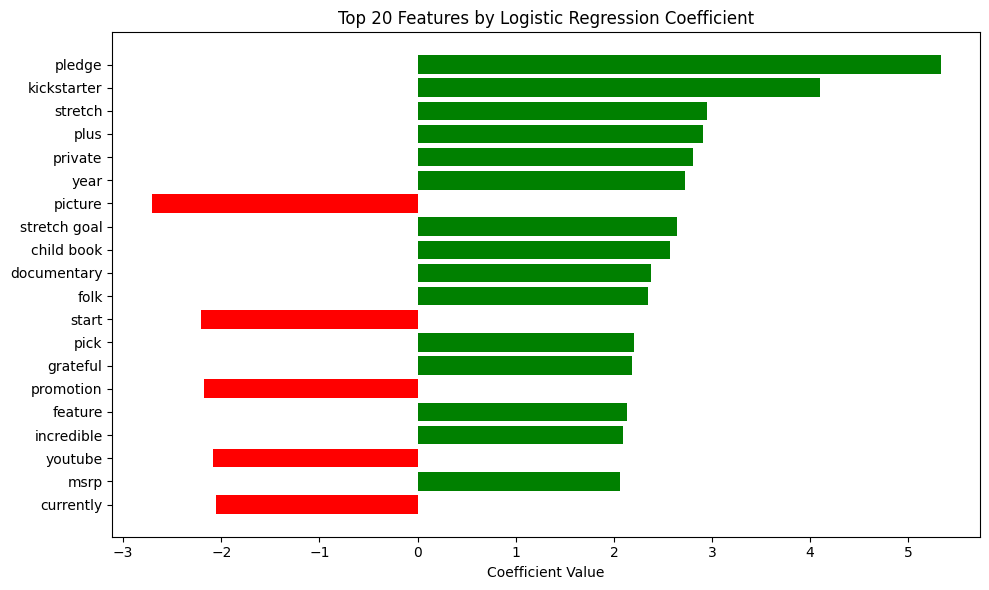

In [23]:
# Top 20 features by absolute coefficient
top_features = coef_df_sorted.head(20)

plt.figure(figsize=(10, 6))
colors = ['green' if c > 0 else 'red' for c in top_features['coef']]  # positive=green, negative=red
plt.barh(top_features['feature'], top_features['coef'], color=colors)
plt.gca().invert_yaxis()  # largest at top
plt.xlabel("Coefficient Value")
plt.title("Top 20 Features by Logistic Regression Coefficient")
plt.tight_layout()
plt.show()

/home/ucloud/.local/lib/python3.12/site-packages/shap/explainers/_linear.py:123: FutureWarning: The feature_perturbation option is now deprecated in favor of using the appropriate masker (maskers.Independent, maskers.Partition or maskers.Impute).
  warnings.warn(wmsg, FutureWarning)


Top 20 features by mean absolute SHAP value:
goal_converted_USD_log                0.893423
num_reward_tiers                      0.374689
video                                 0.280459
prelaunch_activated                   0.161810
campaign_duration_days                0.144419
pledge                                0.132041
total_media_assets                    0.121090
num_static_images                     0.118055
rewards_char_length                   0.113507
category_parent_name_Film & Video     0.096834
currency_USD                          0.079484
country_US                            0.079484
kickstarter                           0.071448
category_parent_name_Music            0.068998
average_number_of_words_per_reward    0.067901
plus                                  0.062706
num_animated_content                  0.059966
film                                  0.051611
book                                  0.046684
launched_day_of_week                  0.045742
dtype: float64


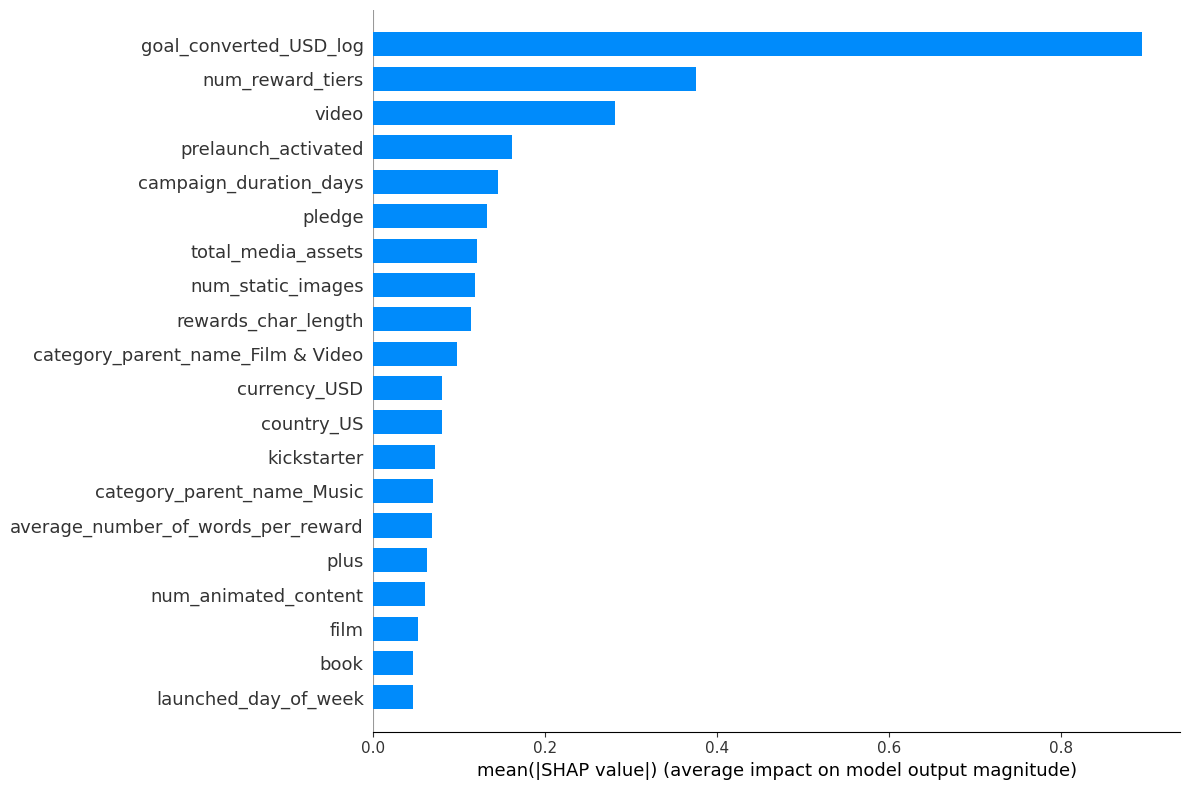

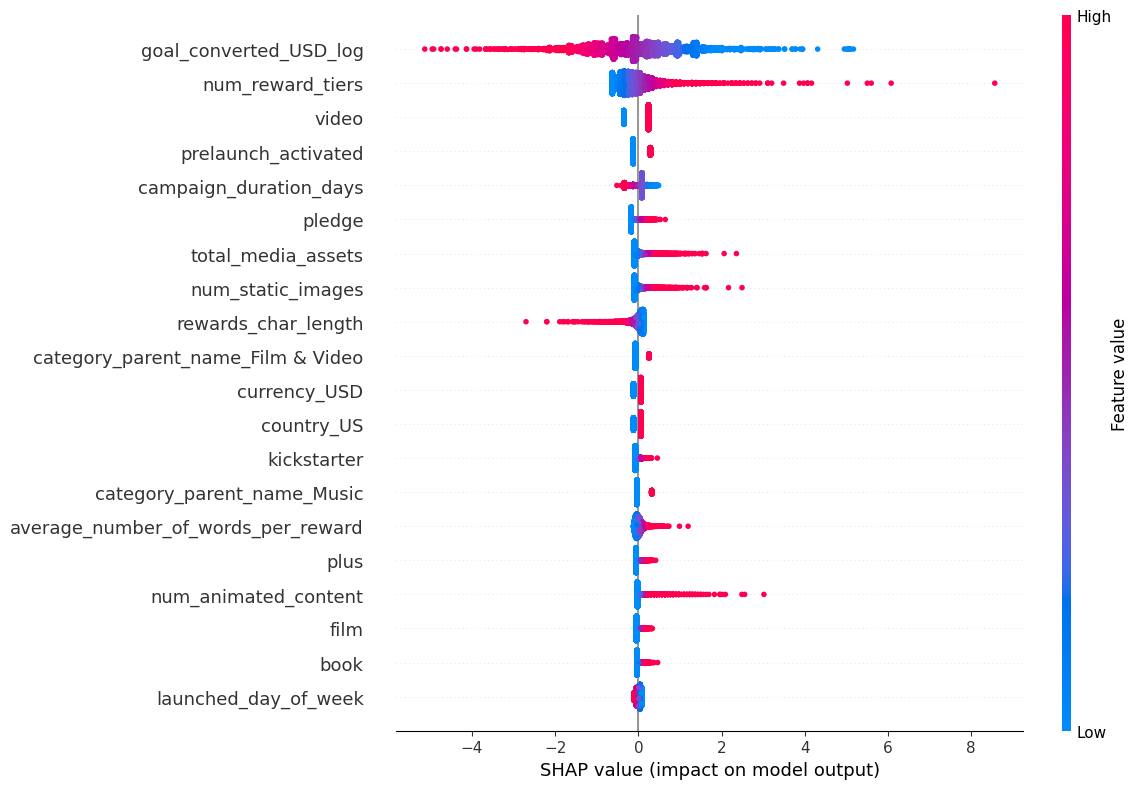

In [ ]:
# Convert TF-IDF matrices to dense DataFrames
X_train_dense = pd.DataFrame(X_train_combined_tfidf.toarray(), columns=combined_feature_names_tfidf)
X_test_dense  = pd.DataFrame(X_test_combined_tfidf.toarray(), columns=combined_feature_names_tfidf)

# Sample background dataset for SHAP
background = X_train_dense.sample(n=min(1000, len(X_train_dense)), random_state=42)

# Create SHAP explainer
explainer = shap.LinearExplainer(lr_model_tfidf, background, feature_perturbation="interventional")

# Compute SHAP values on test set
shap_values = explainer.shap_values(X_test_dense)

# Convert to DataFrame for easy analysis
shap_df = pd.DataFrame(shap_values, columns=X_test_dense.columns)

# Mean absolute SHAP value per feature (common "feature importance" metric)
shap_importance = shap_df.abs().mean().sort_values(ascending=False)

# Show top 10 features overall
print("Top 20 features by mean absolute SHAP value:")
print(shap_importance.head(20))

#Separate textual features
text_features = [f for f in shap_importance.index if f not in metadata_feature_names]
text_shap_importance = shap_importance[text_features]

print("\nTop 20 textual features by mean absolute SHAP value:")
print(text_shap_importance.head(20))

# Bar plot
shap.summary_plot(shap_values, X_test_dense, feature_names=X_test_dense.columns, plot_type="bar", plot_size=(12, 8))

# Dot plot
shap.summary_plot(shap_values, X_test_dense, feature_names=X_test_dense.columns, plot_type="dot", plot_size=(12, 8))

In [24]:
train_auc, test_auc = check_auc_overfitting(lr_model_tfidf, X_train_combined_tfidf, X_test_combined_tfidf, y_train_meta, y_test_meta)

AUC OVERFITTING CHECK:
Train AUC: 0.9382
Test AUC:  0.9038
Difference: 0.0344


In [49]:
# TF-IDF structured + metadata
lr_model_tfidf_structured, lr_shap_tfidf_structured = train_logistic_regression2(
    X_train_tfidf_combined_structured,
    X_val_tfidf_combined_structured,
    X_test_tfidf_combined_structured,
    y_train_meta,
    y_val_meta,
    y_test_meta,
    feature_names=combined_feature_names_tfidf_structured,
    model_name="Logistic Regression (TF-IDF Structured + Metadata)"
)


Training Logistic Regression (TF-IDF Structured + Metadata) with GridSearchCV...
Fitting 5 folds for each of 4 candidates, totalling 20 fits


/home/ucloud/.local/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/ucloud/.local/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/ucloud/.local/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning

[CV] END ...................C=0.01, penalty=l2, solver=lbfgs; total time=   1.1s


/home/ucloud/.local/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


[CV] END ...................C=0.01, penalty=l2, solver=lbfgs; total time=   1.3s


/home/ucloud/.local/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


... (9 outputs left out)

/home/ucloud/.local/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(



Logistic Regression (TF-IDF Structured + Metadata) training and evaluation took: 275.94 seconds

Best parameters: {'C': 0.1, 'penalty': 'l2', 'solver': 'lbfgs'}
Test ROC-AUC: 0.8984030096746423
Test Accuracy: 0.8109493880251406
Classification Report:
               precision    recall  f1-score   support

           0       0.81      0.81      0.81      2962
           1       0.82      0.81      0.81      3084

    accuracy                           0.81      6046
   macro avg       0.81      0.81      0.81      6046
weighted avg       0.81      0.81      0.81      6046



/home/ucloud/.local/lib/python3.12/site-packages/shap/explainers/_linear.py:123: FutureWarning: The feature_perturbation option is now deprecated in favor of using the appropriate masker (maskers.Independent, maskers.Partition or maskers.Impute).
  warnings.warn(wmsg, FutureWarning)



Top 10 features by mean absolute SHAP value:
goal_converted_USD_log                0.828113
num_reward_tiers                      0.447307
video                                 0.265784
campaign_duration_days                0.155000
prelaunch_activated                   0.148687
total_media_assets                    0.139883
num_static_images                     0.137040
rewards_char_length                   0.124050
category_parent_name_Music            0.101409
average_number_of_words_per_reward    0.099151
dtype: float64
rewards_tfidf_pledge       0.084170
rewards_tfidf_plus         0.045704
risks_tfidf_kickstarter    0.038079
risks_tfidf_risk           0.032178
risks_tfidf_book           0.031081
risks_tfidf_challenge      0.029125
story_tfidf_kickstarter    0.028668
story_tfidf_year           0.025742
risks_tfidf_campaign       0.025173
rewards_tfidf_book         0.022891
blurb_tfidf_new            0.021368
rewards_tfidf_print        0.020699
rewards_tfidf_private      0.018787
r

In [ ]:
# Use the trained structured TF-IDF model
coefs = lr_model_tfidf_structured.coef_[0]

coef_df = pd.DataFrame({
    "feature": combined_feature_names_tfidf_structured,
    "coef": coefs
})
coef_df["abs_coef"] = coef_df["coef"].abs()

# Top 20 overall (including metadata)
print("Top 20 features overall (metadata + text):")
print(coef_df.sort_values("abs_coef", ascending=False).head(20))

# Only textual features
text_coef = coef_df[coef_df["feature"].str.contains("_tfidf_")]

# Top positive words per field
print("\nTop 10 positive textual features:")
print(text_coef.sort_values("coef", ascending=False).head(10))

# Top negative words per field
print("\nTop 10 negative textual features:")
print(text_coef.sort_values("coef").head(10))

# top words grouped by field
fields = ["name_tfidf_", "blurb_tfidf_", "story_tfidf_", 
          "risks_tfidf_", "rewards_tfidf_"]

for field in fields:
    print(f"\nTop words in {field}:")
    field_coef = text_coef[text_coef["feature"].str.startswith(field)]
    print(field_coef.sort_values("abs_coef", ascending=False).head(5))

Top 20 features overall (metadata + text):
                       feature      coef  abs_coef
9357      rewards_tfidf_pledge  1.571898  1.571898
9390        rewards_tfidf_plus  1.325395  1.325395
7019   risks_tfidf_kickstarter  1.204266  1.204266
5075   story_tfidf_kickstarter  1.091600  1.091600
62      goal_converted_USD_log -1.059805  1.059805
9464     rewards_tfidf_private  0.992514  0.992514
6078          story_tfidf_year  0.972060  0.972060
5813       story_tfidf_stretch  0.946562  0.946562
6269          risks_tfidf_book  0.916409  0.916409
5814  story_tfidf_stretch goal  0.836701  0.836701
5429        story_tfidf_pledge  0.809650  0.809650
6298      risks_tfidf_campaign  0.798998  0.798998
9328     rewards_tfidf_picture -0.796633  0.796633
2384    blurb_tfidf_child book  0.724838  0.724838
2608   blurb_tfidf_documentary  0.708819  0.708819
7413      risks_tfidf_previous  0.708562  0.708562
7629          risks_tfidf_risk -0.707007  0.707007
5759         story_tfidf_space  0.67089

In [27]:
train_auc, test_auc = check_auc_overfitting(lr_model_tfidf_structured, X_train_tfidf_combined_structured, X_test_tfidf_combined_structured, y_train_meta, y_test_meta)

AUC OVERFITTING CHECK:
Train AUC: 0.9239
Test AUC:  0.8992
Difference: 0.0247


In [27]:
# BoW + metadata
lr_model_bow, lr_shap_bow = train_logistic_regression2(
    X_train_combined_bow, X_val_combined_bow, X_test_combined_bow,
    y_train_meta, y_val_meta, y_test_meta,
    feature_names=combined_feature_names_bow,
    model_name="Logistic Regression (BoW + Metadata)"
)


Training Logistic Regression (BoW + Metadata) with GridSearchCV...
Fitting 5 folds for each of 4 candidates, totalling 20 fits


/home/ucloud/.local/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/ucloud/.local/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/ucloud/.local/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning

[CV] END ...................C=0.01, penalty=l2, solver=lbfgs; total time=   7.5s


/home/ucloud/.local/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


[CV] END ...................C=0.01, penalty=l2, solver=lbfgs; total time=   7.4s
[CV] END ...................C=0.01, penalty=l2, solver=lbfgs; total time=   8.2s
[CV] END ...................C=0.01, penalty=l2, solver=lbfgs; total time=   7.9s
[CV] END ...................C=0.01, penalty=l2, solver=lbfgs; total time=   8.2s


/home/ucloud/.local/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/ucloud/.local/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/ucloud/.local/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning

... (15 outputs left out)

/home/ucloud/.local/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(



Logistic Regression (BoW + Metadata) training and evaluation took: 84.72 seconds

Best parameters: {'C': 0.01, 'penalty': 'l2', 'solver': 'lbfgs'}
Test ROC-AUC: 0.8735816888543252
Test Accuracy: 0.7919285478001985
Classification Report:
               precision    recall  f1-score   support

           0       0.78      0.81      0.79      2962
           1       0.81      0.77      0.79      3084

    accuracy                           0.79      6046
   macro avg       0.79      0.79      0.79      6046
weighted avg       0.79      0.79      0.79      6046



/home/ucloud/.local/lib/python3.12/site-packages/shap/explainers/_linear.py:123: FutureWarning: The feature_perturbation option is now deprecated in favor of using the appropriate masker (maskers.Independent, maskers.Partition or maskers.Impute).
  warnings.warn(wmsg, FutureWarning)



Top 10 features by mean absolute SHAP value:
goal_converted_USD_log    0.892471
num_reward_tiers          0.376558
pledge                    0.295658
video                     0.245888
story_char_length         0.184760
total_media_assets        0.175351
num_static_images         0.172286
kickstarter               0.144675
book                      0.142457
campaign_duration_days    0.140808
dtype: float64
pledge          0.295658
kickstarter     0.144675
book            0.142457
level           0.071226
character       0.071158
exclusive       0.070628
enjoy           0.069137
private         0.064474
record          0.063805
would           0.063686
quality         0.062983
stretch         0.062958
raise           0.061199
start           0.060762
early           0.058961
feature         0.055877
funding         0.054534
previous        0.053651
stretch goal    0.053141
new             0.052032
dtype: float64


In [28]:
train_auc, test_auc = check_auc_overfitting(lr_model_bow, X_train_combined_bow, X_test_combined_bow, y_train_meta, y_test_meta)

AUC OVERFITTING CHECK:
Train AUC: 0.9468
Test AUC:  0.8736
Difference: 0.0732


In [75]:
# BoW structured + metadata
lr_model_bow_structured, lr_shap_bow_structured = train_logistic_regression2(
    X_train_bow_combined_structured,
    X_val_bow_combined_structured,
    X_test_bow_combined_structured,
    y_train_meta,
    y_val_meta,
    y_test_meta,
    feature_names=combined_feature_names_bow_structured,
    model_name="Logistic Regression (BoW Structured + Metadata)"
)


Training Logistic Regression (BoW Structured + Metadata) with GridSearchCV...
Fitting 5 folds for each of 4 candidates, totalling 20 fits


/home/ucloud/.local/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/ucloud/.local/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/ucloud/.local/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning

[CV] END ...................C=0.01, penalty=l2, solver=lbfgs; total time=   6.9s
[CV] END ...................C=0.01, penalty=l2, solver=lbfgs; total time=   7.1s


/home/ucloud/.local/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/ucloud/.local/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


[CV] END ...................C=0.01, penalty=l2, solver=lbfgs; total time=   7.7s


/home/ucloud/.local/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


... (17 outputs left out)

/home/ucloud/.local/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(



Logistic Regression (BoW Structured + Metadata) training and evaluation took: 742.12 seconds

Best parameters: {'C': 0.01, 'penalty': 'l2', 'solver': 'lbfgs'}
Test ROC-AUC: 0.8759736384169213
Test Accuracy: 0.7960635130664903
Classification Report:
               precision    recall  f1-score   support

           0       0.78      0.80      0.79      2962
           1       0.81      0.79      0.80      3084

    accuracy                           0.80      6046
   macro avg       0.80      0.80      0.80      6046
weighted avg       0.80      0.80      0.80      6046



/home/ucloud/.local/lib/python3.12/site-packages/shap/explainers/_linear.py:123: FutureWarning: The feature_perturbation option is now deprecated in favor of using the appropriate masker (maskers.Independent, maskers.Partition or maskers.Impute).
  warnings.warn(wmsg, FutureWarning)



Top 10 features by mean absolute SHAP value:
goal_converted_USD_log    0.880980
num_reward_tiers          0.368132
rewards_bow_pledge        0.265111
video                     0.245049
total_media_assets        0.156423
num_static_images         0.154537
campaign_duration_days    0.136011
story_char_length         0.108791
prelaunch_activated       0.105181
total_text_length         0.098366
dtype: float64
rewards_bow_pledge       0.265111
story_bow_kickstarter    0.097007
risks_bow_kickstarter    0.085477
story_bow_stretch        0.071190
rewards_bow_private      0.067676
story_bow_year           0.060329
story_bow_quality        0.059340
story_bow_reward         0.057704
story_bow_include        0.057560
risks_bow_challenge      0.056546
story_bow_offer          0.056265
story_bow_start          0.055753
story_bow_feature        0.055276
story_bow_story          0.052817
story_bow_character      0.050891
rewards_bow_plus         0.050470
rewards_bow_level        0.050315
story_bow_b

In [76]:
train_auc, test_auc = check_auc_overfitting(lr_model_bow_structured, X_train_bow_combined_structured, X_test_bow_combined_structured, y_train_meta, y_test_meta)

AUC OVERFITTING CHECK:
Train AUC: 0.9514
Test AUC:  0.8760
Difference: 0.0755


In [30]:
# BERT + metadata
lr_model_bert, lr_shap_bert = train_logistic_regression2(
    X_train_combined_bert, X_val_combined_bert, X_test_combined_bert,
    y_train_meta, y_val_meta, y_test_meta,
    feature_names=combined_feature_names_bert,
    model_name="Logistic Regression (BERT + Metadata)"
)


Training Logistic Regression (BERT + Metadata) with GridSearchCV...
Fitting 5 folds for each of 4 candidates, totalling 20 fits


/home/ucloud/.local/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/ucloud/.local/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/ucloud/.local/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning

[CV] END ...................C=0.01, penalty=l2, solver=lbfgs; total time=   0.7s
[CV] END ...................C=0.01, penalty=l2, solver=lbfgs; total time=   0.9s
[CV] END ...................C=0.01, penalty=l2, solver=lbfgs; total time=   0.9s
[CV] END ...................C=0.01, penalty=l2, solver=lbfgs; total time=   0.9s


/home/ucloud/.local/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/ucloud/.local/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/ucloud/.local/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning

[CV] END ...................C=0.01, penalty=l2, solver=lbfgs; total time=   0.9s
[CV] END ....................C=0.1, penalty=l2, solver=lbfgs; total time=   1.5s


/home/ucloud/.local/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


... (11 outputs left out)

/home/ucloud/.local/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(



Logistic Regression (BERT + Metadata) training and evaluation took: 74.69 seconds

Best parameters: {'C': 1, 'penalty': 'l2', 'solver': 'lbfgs'}
Test ROC-AUC: 0.8777181742626665
Test Accuracy: 0.7962289116771419
Classification Report:
               precision    recall  f1-score   support

           0       0.79      0.79      0.79      2962
           1       0.80      0.80      0.80      3084

    accuracy                           0.80      6046
   macro avg       0.80      0.80      0.80      6046
weighted avg       0.80      0.80      0.80      6046



/home/ucloud/.local/lib/python3.12/site-packages/shap/explainers/_linear.py:123: FutureWarning: The feature_perturbation option is now deprecated in favor of using the appropriate masker (maskers.Independent, maskers.Partition or maskers.Impute).
  warnings.warn(wmsg, FutureWarning)



Top 10 features by mean absolute SHAP value:
goal_converted_USD_log        0.837765
num_reward_tiers              0.575875
video                         0.278569
prelaunch_activated           0.203668
campaign_duration_days        0.188957
num_static_images             0.184413
total_media_assets            0.182836
category_parent_name_Music    0.164880
rewards_char_length           0.153011
story_char_length             0.129038
dtype: float64
bert_dim_301    0.112016
bert_dim_291    0.100814
bert_dim_230    0.089883
bert_dim_250    0.088162
bert_dim_24     0.078189
bert_dim_141    0.074468
bert_dim_105    0.072862
bert_dim_79     0.070634
bert_dim_48     0.068303
bert_dim_30     0.067931
bert_dim_176    0.067807
bert_dim_153    0.066402
bert_dim_170    0.064693
bert_dim_46     0.064581
bert_dim_349    0.063676
bert_dim_198    0.063124
bert_dim_28     0.062476
bert_dim_203    0.062125
bert_dim_212    0.060248
bert_dim_243    0.059361
dtype: float64


In [31]:
train_auc, test_auc = check_auc_overfitting(lr_model_bert, X_train_combined_bert, X_test_combined_bert, y_train_meta, y_test_meta)

AUC OVERFITTING CHECK:
Train AUC: 0.8793
Test AUC:  0.8777
Difference: 0.0016
Good generalization: No significant overfitting.


In [77]:
# BERT structured + metadata
lr_model_bert_structured, lr_shap_bert_structured = train_logistic_regression2(
    X_train_bert_combined_structured,
    X_val_bert_combined_structured,
    X_test_bert_combined_structured,
    y_train_meta,
    y_val_meta,
    y_test_meta,
    feature_names=combined_feature_names_bert_structured,
    model_name="Logistic Regression (BERT Structured + Metadata)"
)


Training Logistic Regression (BERT Structured + Metadata) with GridSearchCV...
Fitting 5 folds for each of 4 candidates, totalling 20 fits


/home/ucloud/.local/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/ucloud/.local/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/ucloud/.local/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning

[CV] END ...................C=0.01, penalty=l2, solver=lbfgs; total time=   4.6s
[CV] END ...................C=0.01, penalty=l2, solver=lbfgs; total time=   4.7s
[CV] END ...................C=0.01, penalty=l2, solver=lbfgs; total time=   4.9s
[CV] END ...................C=0.01, penalty=l2, solver=lbfgs; total time=   4.6s
[CV] END ...................C=0.01, penalty=l2, solver=lbfgs; total time=   4.5s


/home/ucloud/.local/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/ucloud/.local/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/ucloud/.local/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning

[CV] END ....................C=0.1, penalty=l2, solver=lbfgs; total time=   8.0s


/home/ucloud/.local/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


... (13 outputs left out)

/home/ucloud/.local/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(



Logistic Regression (BERT Structured + Metadata) training and evaluation took: 98.81 seconds

Best parameters: {'C': 0.1, 'penalty': 'l2', 'solver': 'lbfgs'}
Test ROC-AUC: 0.8901339798274907
Test Accuracy: 0.8044988422097255
Classification Report:
               precision    recall  f1-score   support

           0       0.81      0.79      0.80      2962
           1       0.80      0.82      0.81      3084

    accuracy                           0.80      6046
   macro avg       0.80      0.80      0.80      6046
weighted avg       0.80      0.80      0.80      6046



/home/ucloud/.local/lib/python3.12/site-packages/shap/explainers/_linear.py:123: FutureWarning: The feature_perturbation option is now deprecated in favor of using the appropriate masker (maskers.Independent, maskers.Partition or maskers.Impute).
  warnings.warn(wmsg, FutureWarning)



Top 10 features by mean absolute SHAP value:
goal_converted_USD_log        0.855036
num_reward_tiers              0.405381
video                         0.258864
campaign_duration_days        0.168553
prelaunch_activated           0.166823
num_static_images             0.147961
total_media_assets            0.147411
category_parent_name_Music    0.113390
story_char_length             0.106196
country_US                    0.087560
dtype: float64
rewards_bert_233    0.039200
risks_bert_176      0.032969
risks_bert_361      0.028983
story_bert_250      0.027673
story_bert_141      0.027333
story_bert_291      0.027016
rewards_bert_182    0.026911
rewards_bert_103    0.026136
story_bert_176      0.025240
story_bert_361      0.025069
story_bert_92       0.024957
story_bert_301      0.024882
blurb_bert_79       0.024838
story_bert_321      0.024624
story_bert_230      0.024612
rewards_bert_60     0.024388
story_bert_198      0.024110
rewards_bert_242    0.023907
story_bert_212      0.02364

In [78]:
train_auc, test_auc = check_auc_overfitting(lr_model_bert_structured, X_train_bert_combined_structured, X_test_bert_combined_structured, y_train_meta, y_test_meta)

AUC OVERFITTING CHECK:
Train AUC: 0.8995
Test AUC:  0.8901
Difference: 0.0094
Good generalization: No significant overfitting.


In [32]:
# Fine-tuned BERT + metadata (unstructured)
lr_model_bert_ft_combined, lr_shap_bert_ft_combined = train_logistic_regression2(
    X_train_combined_bert_ft,
    X_val_combined_bert_ft,
    X_test_combined_bert_ft,
    y_train_meta,
    y_val_meta,
    y_test_meta,
    feature_names=combined_feature_names_bert_ft,
    model_name="Logistic Regression (BERT FT + Metadata)"
)


Training Logistic Regression (BERT FT + Metadata) with GridSearchCV...
Fitting 5 folds for each of 4 candidates, totalling 20 fits


/home/ucloud/.local/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/ucloud/.local/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/ucloud/.local/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning

[CV] END ...................C=0.01, penalty=l2, solver=lbfgs; total time=   1.0s


/home/ucloud/.local/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


[CV] END ...................C=0.01, penalty=l2, solver=lbfgs; total time=   1.3s
[CV] END ...................C=0.01, penalty=l2, solver=lbfgs; total time=   1.4s
[CV] END ...................C=0.01, penalty=l2, solver=lbfgs; total time=   1.4s
[CV] END ...................C=0.01, penalty=l2, solver=lbfgs; total time=   1.5s


/home/ucloud/.local/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/ucloud/.local/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/ucloud/.local/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning

... (9 outputs left out)

/home/ucloud/.local/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(



Logistic Regression (BERT FT + Metadata) training and evaluation took: 43.60 seconds

Best parameters: {'C': 0.1, 'penalty': 'l2', 'solver': 'lbfgs'}
Test ROC-AUC: 0.8893975658820634
Test Accuracy: 0.8026794574925571
Classification Report:
               precision    recall  f1-score   support

           0       0.80      0.80      0.80      2962
           1       0.81      0.80      0.81      3084

    accuracy                           0.80      6046
   macro avg       0.80      0.80      0.80      6046
weighted avg       0.80      0.80      0.80      6046



/home/ucloud/.local/lib/python3.12/site-packages/shap/explainers/_linear.py:123: FutureWarning: The feature_perturbation option is now deprecated in favor of using the appropriate masker (maskers.Independent, maskers.Partition or maskers.Impute).
  warnings.warn(wmsg, FutureWarning)



Top 10 features by mean absolute SHAP value:
goal_converted_USD_log    0.784104
bert_ft_dim_129           0.303337
bert_ft_dim_131           0.300315
num_reward_tiers          0.291653
bert_ft_dim_112           0.265745
video                     0.253350
bert_ft_dim_88            0.204478
bert_ft_dim_189           0.185469
bert_ft_dim_96            0.185345
bert_ft_dim_164           0.169935
dtype: float64
bert_ft_dim_129    0.303337
bert_ft_dim_131    0.300315
bert_ft_dim_112    0.265745
bert_ft_dim_88     0.204478
bert_ft_dim_189    0.185469
bert_ft_dim_96     0.185345
bert_ft_dim_164    0.169935
bert_ft_dim_108    0.153253
bert_ft_dim_51     0.146340
bert_ft_dim_244    0.143699
bert_ft_dim_4      0.141762
bert_ft_dim_87     0.140140
bert_ft_dim_86     0.137152
bert_ft_dim_194    0.133321
bert_ft_dim_92     0.133017
bert_ft_dim_6      0.131071
bert_ft_dim_139    0.129629
bert_ft_dim_22     0.122541
bert_ft_dim_237    0.121751
bert_ft_dim_18     0.115770
dtype: float64


In [33]:
train_auc, test_auc = check_auc_overfitting(lr_model_bert_ft_combined, X_train_combined_bert_ft, X_test_combined_bert_ft, y_train_meta, y_test_meta)

AUC OVERFITTING CHECK:
Train AUC: 0.9368
Test AUC:  0.8894
Difference: 0.0474


In [79]:
# Fine-tuned BERT structured + metadata
lr_model_bert_ft_structured, lr_shap_bert_ft_structured = train_logistic_regression2(
    X_train_combined_bert_ft_structured,
    X_val_combined_bert_ft_structured,
    X_test_combined_bert_ft_structured,
    y_train_meta,
    y_val_meta,
    y_test_meta,
    feature_names=combined_feature_names_bert_ft_structured,
    model_name="Logistic Regression (BERT FT Structured + Metadata)"
)


Training Logistic Regression (BERT FT Structured + Metadata) with GridSearchCV...
Fitting 5 folds for each of 4 candidates, totalling 20 fits


/home/ucloud/.local/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/ucloud/.local/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/ucloud/.local/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning

[CV] END ...................C=0.01, penalty=l2, solver=lbfgs; total time=   3.5s
[CV] END ...................C=0.01, penalty=l2, solver=lbfgs; total time=   3.5s


/home/ucloud/.local/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/ucloud/.local/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


[CV] END ...................C=0.01, penalty=l2, solver=lbfgs; total time=   4.2s
[CV] END ...................C=0.01, penalty=l2, solver=lbfgs; total time=   4.3s


/home/ucloud/.local/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/ucloud/.local/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


... (15 outputs left out)

/home/ucloud/.local/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(



Logistic Regression (BERT FT Structured + Metadata) training and evaluation took: 82.46 seconds

Best parameters: {'C': 0.01, 'penalty': 'l2', 'solver': 'lbfgs'}
Test ROC-AUC: 0.8982574127447452
Test Accuracy: 0.8124379755210056
Classification Report:
               precision    recall  f1-score   support

           0       0.81      0.81      0.81      2962
           1       0.82      0.82      0.82      3084

    accuracy                           0.81      6046
   macro avg       0.81      0.81      0.81      6046
weighted avg       0.81      0.81      0.81      6046



/home/ucloud/.local/lib/python3.12/site-packages/shap/explainers/_linear.py:123: FutureWarning: The feature_perturbation option is now deprecated in favor of using the appropriate masker (maskers.Independent, maskers.Partition or maskers.Impute).
  warnings.warn(wmsg, FutureWarning)



Top 10 features by mean absolute SHAP value:
goal_converted_USD_log    0.749108
video                     0.208023
num_reward_tiers          0.168246
campaign_duration_days    0.115686
total_media_assets        0.097649
prelaunch_activated       0.091666
story_bert_ft_88          0.089672
num_static_images         0.089247
story_bert_ft_129         0.074939
num_animated_content      0.071506
dtype: float64
story_bert_ft_88       0.089672
story_bert_ft_129      0.074939
story_bert_ft_108      0.063860
story_bert_ft_40       0.059897
story_bert_ft_61       0.057962
story_bert_ft_96       0.057176
story_bert_ft_189      0.056129
story_bert_ft_176      0.052441
story_bert_ft_162      0.051026
rewards_bert_ft_112    0.049596
rewards_bert_ft_4      0.047357
story_bert_ft_152      0.046393
rewards_bert_ft_61     0.045764
story_bert_ft_86       0.044788
story_bert_ft_139      0.044640
rewards_bert_ft_142    0.044176
story_bert_ft_254      0.043751
rewards_bert_ft_108    0.043019
rewards_bert_

In [80]:
train_auc, test_auc = check_auc_overfitting(lr_model_bert_ft_structured, X_train_combined_bert_ft_structured, X_test_combined_bert_ft_structured, y_train_meta, y_test_meta)

AUC OVERFITTING CHECK:
Train AUC: 0.9260
Test AUC:  0.8983
Difference: 0.0277


SVM

In [ ]:
def train_svm2(X_train, X_val, X_test, y_train, y_val, y_test, feature_names,
                model_name="SVM (GridSearch)"):

    print(f"\nTraining {model_name} with GridSearchCV...")
    start_time = time.time()

    # Base Linear SVM
    svm_base = LinearSVC(
        class_weight='balanced',
        random_state=42,
        dual=False,
        max_iter=10000
    )

    # Hyperparameter grid
    param_grid = {'C': [0.001, 0.01, 0.1, 1]}

    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

    grid = GridSearchCV(
        estimator=svm_base,
        param_grid=param_grid,
        scoring='roc_auc',
        cv=cv,
        verbose=1
        n_jobs=-1
    )

    # Fit GridSearch to find best hyperparameters
    grid.fit(X_train, y_train)
    best_linear_svc = grid.best_estimator_

    print("Best parameters:", grid.best_params_)

    # calibrate the SVM using Platt scaling (sigmoid)
    svm_calibrated = CalibratedClassifierCV(
        best_linear_svc,
        method='sigmoid',
        cv=5
    )
    svm_calibrated.fit(X_train, y_train)

    # Predict on test set
    y_pred = svm_calibrated.predict(X_test)
    y_pred_proba = svm_calibrated.predict_proba(X_test)[:, 1]

    end_time = time.time()
    print(f"\n{model_name} training and evaluation took: {end_time - start_time:.2f} seconds")

    # Metrics
    print("Test ROC-AUC:", roc_auc_score(y_test, y_pred_proba))
    print(f"Test Accuracy: {accuracy_score(y_test, y_pred):.4f}")
    print("Classification Report:\n", classification_report(y_test, y_pred))

    # Feature importance analysis using coefficients
    underlying_coefs = svm_calibrated.calibrated_classifiers_[0].estimator.coef_[0]
    
    feature_importance = pd.DataFrame({
        'feature': feature_names,
        'importance': underlying_coefs
    }).sort_values('importance', key=abs, ascending=False)

    print("\nTop 20 features by coefficient magnitude:")
    print(feature_importance.head(20))

    return svm_calibrated, feature_importance

In [28]:
# TF-IDF + meta
svm_model_tfidf, svm_shap_tfidf = train_svm2(
    X_train_combined_tfidf, X_val_combined_tfidf, X_test_combined_tfidf,
    y_train_meta, y_val_meta, y_test_meta,
    feature_names=combined_feature_names_tfidf,
    model_name="SVM (TF-IDF + Metadata)"
)


Training SVM (TF-IDF + Metadata) with GridSearchCV...
Fitting 5 folds for each of 4 candidates, totalling 20 fits


Best parameters: {'C': 0.1}

SVM (TF-IDF + Metadata) training and evaluation took: 100.34 seconds
Test ROC-AUC: 0.9037735659030819
Test Accuracy: 0.8171
Classification Report:
               precision    recall  f1-score   support

           0       0.82      0.81      0.81      2962
           1       0.82      0.83      0.82      3084

    accuracy                           0.82      6046
   macro avg       0.82      0.82      0.82      6046
weighted avg       0.82      0.82      0.82      6046


Top 10 features by coefficient magnitude:
           feature  importance
5296        pledge    1.819073
3875   kickstarter    1.341600
6966       stretch    1.069270
5578       private    1.031874
5363          plus    1.030247
5215       picture   -1.020573
6967  stretch goal    1.008764
1828     currently   -0.851763
1297    child book    0.851439
6862         start   -0.822771
8040          year    0.822101
5694     promotion   -0.819163
1102      campaign    0.813454
2850          folk 

In [ ]:
# absolute value of coefficients for sorting
svm_shap_tfidf['abs_coef'] = svm_shap_tfidf['importance'].abs()

# Overall top 20 features
top20 = svm_shap_tfidf.sort_values('abs_coef', ascending=False).head(20)
print("Top 20 features overall (metadata + text):")
print(top20)

# Filter to keep only textual features
text_only = svm_shap_tfidf[~svm_shap_tfidf['feature'].isin(metadata_feature_names)]

# Top 10 positive textual features
top10_text_pos = text_only.sort_values('importance', ascending=False).head(10)
print("\nTop 10 positive textual features:")
print(top10_text_pos)

# Top 10 negative textual features
top10_text_neg = text_only.sort_values('importance').head(10)
print("\nTop 10 negative textual features:")
print(top10_text_neg)

Top 20 features overall (metadata + text):
           feature  importance  abs_coef
5296        pledge    1.819073  1.819073
3875   kickstarter    1.341600  1.341600
6966       stretch    1.069270  1.069270
5578       private    1.031874  1.031874
5363          plus    1.030247  1.030247
5215       picture   -1.020573  1.020573
6967  stretch goal    1.008764  1.008764
1828     currently   -0.851763  0.851763
1297    child book    0.851439  0.851439
6862         start   -0.822771  0.822771
8040          year    0.822101  0.822101
5694     promotion   -0.819163  0.819163
1102      campaign    0.813454  0.813454
2850          folk    0.805950  0.805950
2155   documentary    0.801128  0.801128
2695       feature    0.799573  0.799573
3182      grateful    0.787191  0.787191
5211          pick    0.769972  0.769972
8076       youtube   -0.754030  0.754030
5266          plan   -0.743056  0.743056

Top 10 positive textual features:
           feature  importance  abs_coef
5296        pledge  

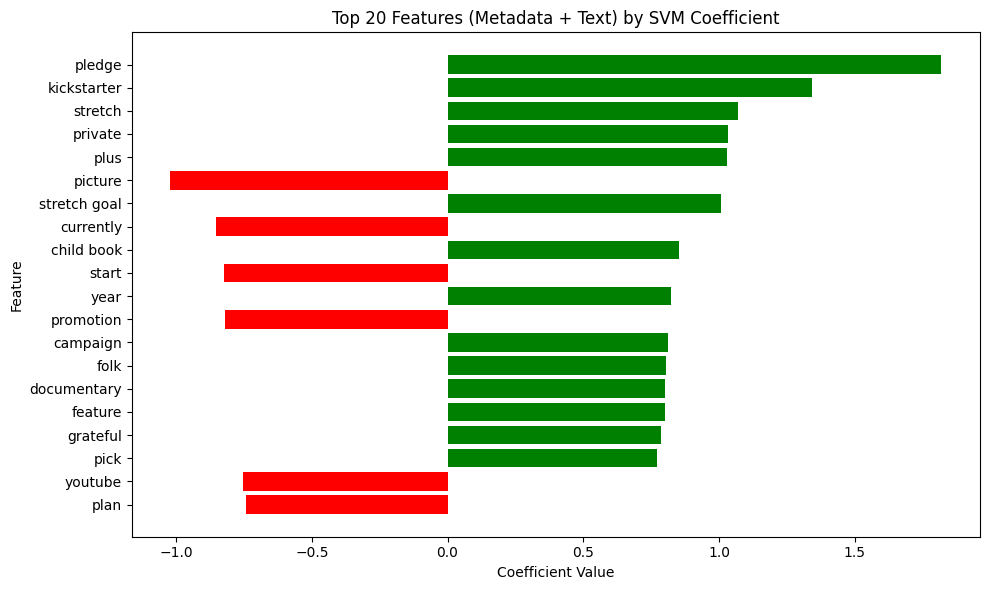

In [34]:
# Top 20 features by absolute coefficient magnitude
top20 = svm_shap_tfidf.sort_values('abs_coef', ascending=False).head(20)

plt.figure(figsize=(10, 6))

# Green for positive (toward success), red for negative (toward failure)
colors = ['green' if val > 0 else 'red' for val in top20['importance']]

plt.barh(top20['feature'], top20['importance'], color=colors)
plt.gca().invert_yaxis()  # largest on top
plt.xlabel("Coefficient Value")
plt.ylabel("Feature")
plt.title("Top 20 Features (Metadata + Text) by SVM Coefficient")
plt.tight_layout()
plt.show()

In [84]:
train_auc, test_auc = check_auc_overfitting(svm_model_tfidf, X_train_combined_tfidf, X_test_combined_tfidf, y_train_meta, y_test_meta)

AUC OVERFITTING CHECK:
Train AUC: 0.9367
Test AUC:  0.9038
Difference: 0.0329


/home/ucloud/.local/lib/python3.12/site-packages/shap/explainers/_linear.py:123: FutureWarning: The feature_perturbation option is now deprecated in favor of using the appropriate masker (maskers.Independent, maskers.Partition or maskers.Impute).
  warnings.warn(wmsg, FutureWarning)


Top 10 features by mean absolute SHAP value:
goal_converted_USD_log                0.300565
num_reward_tiers                      0.127386
video                                 0.094641
prelaunch_activated                   0.056015
campaign_duration_days                0.054620
pledge                                0.045077
total_media_assets                    0.040646
num_static_images                     0.039167
rewards_char_length                   0.035423
currency_EUR                          0.028502
kickstarter                           0.023376
category_parent_name_Music            0.023028
category_parent_name_Film & Video     0.022563
plus                                  0.022190
film                                  0.021980
num_animated_content                  0.021671
location_type_Town                    0.021518
average_number_of_words_per_reward    0.021134
book                                  0.019869
category_parent_name_Publishing       0.017295
dtype: float64


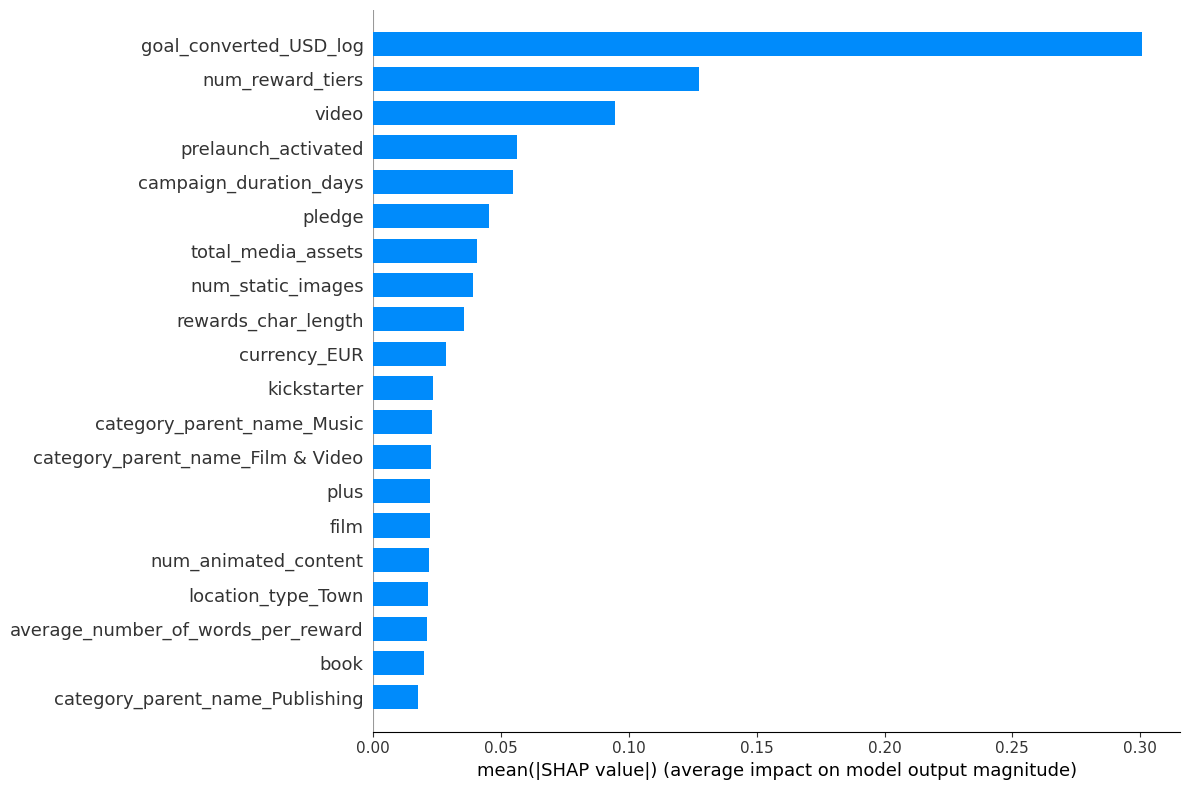

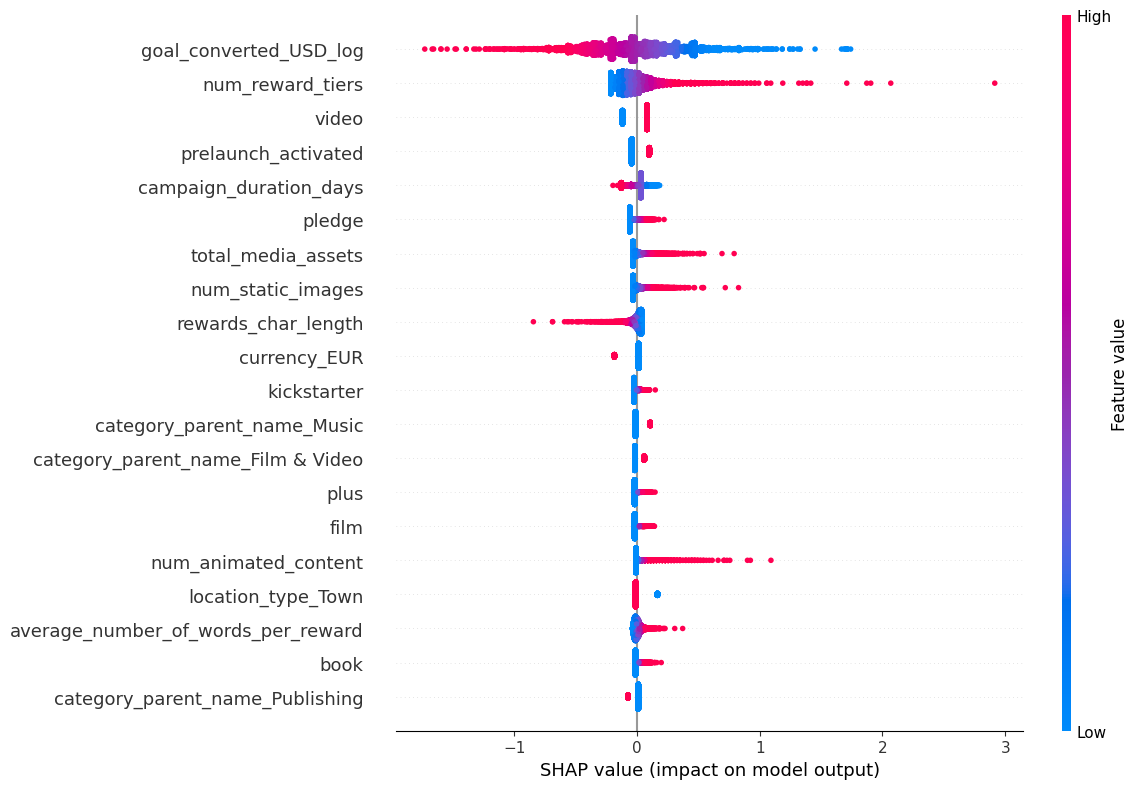

In [ ]:
# Get the underlying LinearSVC from the calibrated SVM
linear_svc = svm_model_tfidf.calibrated_classifiers_[0].estimator

# Convert sparse TF-IDF matrices to dense DataFrames for SHAP
X_train_dense = pd.DataFrame(X_train_combined_tfidf.toarray(), columns=combined_feature_names_tfidf)
X_test_dense  = pd.DataFrame(X_test_combined_tfidf.toarray(), columns=combined_feature_names_tfidf)

# Sample a background dataset for SHAP
background = X_train_dense.sample(n=1000, random_state=42)

# Create SHAP explainer
explainer = shap.LinearExplainer(linear_svc, background, feature_perturbation="interventional")

# Compute SHAP values on test set
shap_values = explainer.shap_values(X_test_dense)

# Convert to DataFrame
shap_df = pd.DataFrame(shap_values, columns=combined_feature_names_tfidf)

# Mean absolute SHAP value per feature (feature importance)
shap_importance = shap_df.abs().mean().sort_values(ascending=False)

# Show top 10 features
print("Top 10 features by mean absolute SHAP value:")
print(shap_importance.head(20))

# SHAP summary plots
# Bar plot
shap.summary_plot(shap_values, X_test_dense, feature_names=combined_feature_names_tfidf, plot_type="bar", plot_size=(12, 8))

# Dot plot
shap.summary_plot(shap_values, X_test_dense, feature_names=combined_feature_names_tfidf, plot_type="dot", plot_size=(12, 8))

In [86]:
# TF-IDF structured + metadata
svm_model_tfidf_structured, svm_shap_tfidf_structured = train_svm2(
    X_train_tfidf_combined_structured,
    X_val_tfidf_combined_structured,
    X_test_tfidf_combined_structured,
    y_train_meta,
    y_val_meta,
    y_test_meta,
    feature_names=combined_feature_names_tfidf_structured,
    model_name="SVM (TF-IDF Structured + Metadata)"
)


Training SVM (TF-IDF Structured + Metadata) with GridSearchCV...
Fitting 5 folds for each of 4 candidates, totalling 20 fits
Best parameters: {'C': 0.01}

SVM (TF-IDF Structured + Metadata) training and evaluation took: 687.17 seconds
Test ROC-AUC: 0.8979193651360816
Test Accuracy: 0.8105
Classification Report:
               precision    recall  f1-score   support

           0       0.81      0.80      0.81      2962
           1       0.81      0.82      0.81      3084

    accuracy                           0.81      6046
   macro avg       0.81      0.81      0.81      6046
weighted avg       0.81      0.81      0.81      6046


Top 10 features by coefficient magnitude:
                       feature  importance
9357      rewards_tfidf_pledge    0.506473
9390        rewards_tfidf_plus    0.469482
7019   risks_tfidf_kickstarter    0.431619
62      goal_converted_USD_log   -0.365352
9464     rewards_tfidf_private    0.353833
5075   story_tfidf_kickstarter    0.343434
5813       sto

In [87]:
train_auc, test_auc = check_auc_overfitting(svm_model_tfidf_structured, X_train_tfidf_combined_structured, X_test_tfidf_combined_structured, y_train_meta, y_test_meta)

AUC OVERFITTING CHECK:
Train AUC: 0.9209
Test AUC:  0.8979
Difference: 0.0230


In [88]:
# Bow + meta
svm_model_bow, svm_shap_bow = train_svm2(
    X_train_combined_bow, X_val_combined_bow, X_test_combined_bow,
    y_train_meta, y_val_meta, y_test_meta,
    feature_names=combined_feature_names_bow,
    model_name="SVM (BoW + Metadata)"
)


Training SVM (BoW + Metadata) with GridSearchCV...
Fitting 5 folds for each of 4 candidates, totalling 20 fits
Best parameters: {'C': 0.001}

SVM (BoW + Metadata) training and evaluation took: 629.76 seconds
Test ROC-AUC: 0.8768334266029456
Test Accuracy: 0.7942
Classification Report:
               precision    recall  f1-score   support

           0       0.78      0.81      0.79      2962
           1       0.81      0.78      0.79      3084

    accuracy                           0.79      6046
   macro avg       0.79      0.79      0.79      6046
weighted avg       0.79      0.79      0.79      6046


Top 10 features by coefficient magnitude:
                         feature  importance
62        goal_converted_USD_log   -0.385523
81              num_reward_tiers    0.201058
90                         video    0.189523
87             story_char_length    0.133743
83           prelaunch_activated    0.122737
89             total_text_length    0.112490
50                  currenc

In [89]:
train_auc, test_auc = check_auc_overfitting(svm_model_bow, X_train_combined_bow, X_test_combined_bow, y_train_meta, y_test_meta)

AUC OVERFITTING CHECK:
Train AUC: 0.9465
Test AUC:  0.8768
Difference: 0.0696


In [90]:
# BoW structured + metadata
svm_model_bow_structured, svm_shap_bow_structured = train_svm2(
    X_train_bow_combined_structured,
    X_val_bow_combined_structured,
    X_test_bow_combined_structured,
    y_train_meta,
    y_val_meta,
    y_test_meta,
    feature_names=combined_feature_names_bow_structured,
    model_name="SVM (BoW Structured + Metadata)"
)


Training SVM (BoW Structured + Metadata) with GridSearchCV...
Fitting 5 folds for each of 4 candidates, totalling 20 fits


/home/ucloud/.local/lib/python3.12/site-packages/sklearn/svm/_base.py:1258: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/home/ucloud/.local/lib/python3.12/site-packages/sklearn/svm/_base.py:1258: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/home/ucloud/.local/lib/python3.12/site-packages/sklearn/svm/_base.py:1258: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/home/ucloud/.local/lib/python3.12/site-packages/sklearn/svm/_base.py:1258: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/home/ucloud/.local/lib/python3.12/site-packages/sklearn/svm/_base.py:1258: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


Best parameters: {'C': 0.001}

SVM (BoW Structured + Metadata) training and evaluation took: 2355.85 seconds
Test ROC-AUC: 0.8780488872891472
Test Accuracy: 0.7947
Classification Report:
               precision    recall  f1-score   support

           0       0.78      0.80      0.79      2962
           1       0.81      0.79      0.80      3084

    accuracy                           0.79      6046
   macro avg       0.79      0.79      0.79      6046
weighted avg       0.80      0.79      0.79      6046


Top 10 features by coefficient magnitude:
                        feature  importance
62       goal_converted_USD_log   -0.379431
81             num_reward_tiers    0.199747
90                        video    0.189138
50                 currency_EUR   -0.117604
89            total_text_length    0.103322
83          prelaunch_activated    0.102936
87            story_char_length    0.100793
5   category_parent_name_Crafts   -0.097995
13   category_parent_name_Music    0.083394
88

In [91]:
train_auc, test_auc = check_auc_overfitting(svm_model_bow_structured, X_train_bow_combined_structured, X_test_bow_combined_structured, y_train_meta, y_test_meta)

AUC OVERFITTING CHECK:
Train AUC: 0.9505
Test AUC:  0.8780
Difference: 0.0724


In [92]:
# BERT + meta
svm_model_bert, svm_shap_bert = train_svm2(
    X_train_combined_bert, X_val_combined_bert, X_test_combined_bert,
    y_train_meta, y_val_meta, y_test_meta,
    feature_names=combined_feature_names_bert,
    model_name="SVM (BERT + Metadata)"
)


Training SVM (BERT + Metadata) with GridSearchCV...
Fitting 5 folds for each of 4 candidates, totalling 20 fits
Best parameters: {'C': 0.1}

SVM (BERT + Metadata) training and evaluation took: 107.52 seconds
Test ROC-AUC: 0.8777395211809595
Test Accuracy: 0.7936
Classification Report:
               precision    recall  f1-score   support

           0       0.80      0.78      0.79      2962
           1       0.79      0.81      0.80      3084

    accuracy                           0.79      6046
   macro avg       0.79      0.79      0.79      6046
weighted avg       0.79      0.79      0.79      6046


Top 10 features by coefficient magnitude:
          feature  importance
392  bert_dim_301   -1.050433
382  bert_dim_291   -0.932322
115   bert_dim_24    0.902636
321  bert_dim_230    0.799401
341  bert_dim_250    0.726314
119   bert_dim_28   -0.714900
139   bert_dim_48   -0.711670
170   bert_dim_79   -0.699507
442  bert_dim_351    0.693041
294  bert_dim_203   -0.691795


In [93]:
train_auc, test_auc = check_auc_overfitting(svm_model_bert, X_train_combined_bert, X_test_combined_bert, y_train_meta, y_test_meta)

AUC OVERFITTING CHECK:
Train AUC: 0.8790
Test AUC:  0.8777
Difference: 0.0013
Good generalization: No significant overfitting.


In [94]:
# BERT structured + metadata
svm_model_bert_structured, svm_shap_bert_structured = train_svm2(
    X_train_bert_combined_structured,
    X_val_bert_combined_structured,
    X_test_bert_combined_structured,
    y_train_meta,
    y_val_meta,
    y_test_meta,
    feature_names=combined_feature_names_bert_structured,
    model_name="SVM (BERT Structured + Metadata)"
)


Training SVM (BERT Structured + Metadata) with GridSearchCV...
Fitting 5 folds for each of 4 candidates, totalling 20 fits
Best parameters: {'C': 0.01}

SVM (BERT Structured + Metadata) training and evaluation took: 294.38 seconds
Test ROC-AUC: 0.8898411438970584
Test Accuracy: 0.8062
Classification Report:
               precision    recall  f1-score   support

           0       0.81      0.79      0.80      2962
           1       0.80      0.82      0.81      3084

    accuracy                           0.81      6046
   macro avg       0.81      0.81      0.81      6046
weighted avg       0.81      0.81      0.81      6046


Top 10 features by coefficient magnitude:
                          feature  importance
62         goal_converted_USD_log   -0.379736
1860             rewards_bert_233   -0.354581
1809             rewards_bert_182   -0.296979
6      category_parent_name_Dance    0.295972
5     category_parent_name_Crafts   -0.265754
1604               risks_bert_361   -0.2587

In [95]:
train_auc, test_auc = check_auc_overfitting(svm_model_bert_structured, X_train_bert_combined_structured, X_test_bert_combined_structured, y_train_meta, y_test_meta)

AUC OVERFITTING CHECK:
Train AUC: 0.8986
Test AUC:  0.8898
Difference: 0.0087
Good generalization: No significant overfitting.


In [96]:
# Fine-tuned BERT unstructured + metadata
svm_model_bert_ft, svm_shap_bert_ft = train_svm2(
    X_train_combined_bert_ft,
    X_val_combined_bert_ft,
    X_test_combined_bert_ft,
    y_train_meta,
    y_val_meta,
    y_test_meta,
    feature_names=combined_feature_names_bert_ft,
    model_name="SVM (Fine-tuned BERT + Metadata)"
)


Training SVM (Fine-tuned BERT + Metadata) with GridSearchCV...
Fitting 5 folds for each of 4 candidates, totalling 20 fits


Best parameters: {'C': 0.01}

SVM (Fine-tuned BERT + Metadata) training and evaluation took: 25.93 seconds
Test ROC-AUC: 0.8875205696715246
Test Accuracy: 0.8012
Classification Report:
               precision    recall  f1-score   support

           0       0.80      0.80      0.80      2962
           1       0.80      0.81      0.81      3084

    accuracy                           0.80      6046
   macro avg       0.80      0.80      0.80      6046
weighted avg       0.80      0.80      0.80      6046


Top 10 features by coefficient magnitude:
                    feature  importance
62   goal_converted_USD_log   -0.303263
220         bert_ft_dim_129   -0.269367
203         bert_ft_dim_112    0.206435
254         bert_ft_dim_163    0.200289
187          bert_ft_dim_96    0.198942
280         bert_ft_dim_189   -0.192558
222         bert_ft_dim_131   -0.185122
179          bert_ft_dim_88   -0.184918
97            bert_ft_dim_6   -0.178655
90                    video    0.173347


In [97]:
train_auc, test_auc = check_auc_overfitting(svm_model_bert_ft, X_train_combined_bert_ft, X_test_combined_bert_ft, y_train_meta, y_test_meta)

AUC OVERFITTING CHECK:
Train AUC: 0.9362
Test AUC:  0.8875
Difference: 0.0487


In [98]:
# Fine-tuned BERT structured + metadata
svm_model_bert_ft_structured, svm_shap_bert_ft_structured = train_svm2(
    X_train_combined_bert_ft_structured,
    X_val_combined_bert_ft_structured,
    X_test_combined_bert_ft_structured,
    y_train_meta,
    y_val_meta,
    y_test_meta,
    feature_names=combined_feature_names_bert_ft_structured,
    model_name="SVM (Fine-tuned BERT Structured + Metadata)"
)


Training SVM (Fine-tuned BERT Structured + Metadata) with GridSearchCV...
Fitting 5 folds for each of 4 candidates, totalling 20 fits
Best parameters: {'C': 0.001}

SVM (Fine-tuned BERT Structured + Metadata) training and evaluation took: 87.73 seconds
Test ROC-AUC: 0.8968493919084014
Test Accuracy: 0.8105
Classification Report:
               precision    recall  f1-score   support

           0       0.81      0.80      0.81      2962
           1       0.81      0.82      0.81      3084

    accuracy                           0.81      6046
   macro avg       0.81      0.81      0.81      6046
weighted avg       0.81      0.81      0.81      6046


Top 10 features by coefficient magnitude:
                              feature  importance
62             goal_converted_USD_log   -0.308783
90                              video    0.155239
1257              rewards_bert_ft_142   -0.090015
691                  story_bert_ft_88   -0.086857
83                prelaunch_activated    0.0856

In [99]:
train_auc, test_auc = check_auc_overfitting(svm_model_bert_ft_structured, X_train_combined_bert_ft_structured, X_test_combined_bert_ft_structured, y_train_meta, y_test_meta)

AUC OVERFITTING CHECK:
Train AUC: 0.9251
Test AUC:  0.8968
Difference: 0.0283


In [ ]:
# For reference
# text only svm + bow
svm_model_bow_textonly, svm_shap_bow_textonly = train_svm2(
    X_text_train_bow, X_text_val_bow, X_text_test_bow,
    y_train_meta, y_val_meta, y_test_meta,
    feature_names=text_feature_names_bow,
    model_name="SVM (BoW Text Only)"
)


Training SVM (BoW Text Only) with GridSearchCV...
Fitting 5 folds for each of 4 candidates, totalling 20 fits


Best parameters: {'C': 0.001}

SVM (BoW Text Only) training and evaluation took: 294.47 seconds
Test ROC-AUC: 0.8351558127986927
Test Accuracy: 0.7635
Classification Report:
               precision    recall  f1-score   support

           0       0.73      0.82      0.77      2962
           1       0.80      0.71      0.75      3084

    accuracy                           0.76      6046
   macro avg       0.77      0.76      0.76      6046
weighted avg       0.77      0.76      0.76      6046


Top 10 features by coefficient magnitude:
                     feature  importance
750               child book    0.118759
1020              cover cost    0.088931
4323  successful kickstarter    0.085525
4965                      x2    0.078181
4540                titanium    0.076155
3942                  senior    0.072378
4155              song write    0.070569
519                book plus   -0.070242
1982                grateful    0.069166
1298                downtown    0.069098


In [ ]:
train_auc, test_auc = check_auc_overfitting(svm_model_bow_textonly, X_text_train_bow, X_text_test_bow, y_train_meta, y_test_meta)

AUC OVERFITTING CHECK:
Train AUC: 0.9204
Test AUC:  0.8352
Difference: 0.0852


XGBoost

In [ ]:
def train_xgboost2(X_train, X_val, X_test,
                   y_train, y_val, y_test,
                   feature_names,
                   model_name="XGBoost (RandomizedSearch)"):

    print(f"\nTraining {model_name} with RandomizedSearchCV...")
    start_time = time.time()

    # Base model
    clf = xgb.XGBClassifier(
        objective='binary:logistic',
        eval_metric='auc',
        subsample=0.8,
        colsample_bytree=0.8,
        random_state=42,
        n_jobs=1
    )

    # Hyperparameter space
    param_grid = {
        'n_estimators': [300, 500],
        'max_depth': [4, 5],
        'learning_rate': [0.01, 0.05, 0.1],
        'gamma': [0, 0.1, 0.2],
        'min_child_weight': [1, 3, 5]
    }

    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

    grid = RandomizedSearchCV(
        estimator=clf,
        param_distributions=param_grid,
        n_iter=10,
        scoring='roc_auc',
        cv=cv,
        verbose=3,
        n_jobs=-1,
        random_state=42
    )

    # Run hyperparameter search
    grid.fit(X_train, y_train)

    search_time = time.time()
    print(f"\nHyperparameter search time: {search_time - start_time:.2f} seconds")

    print("\nBest parameters found:")
    print(grid.best_params_)

    print("\nTraining final model with early stopping and live progress...\n")

    best_model = grid.best_estimator_

    best_model.set_params(early_stopping_rounds=50)

    best_model.fit(
        X_train,
        y_train,
        eval_set=[(X_val, y_val)],
        verbose=True
    )

    end_time = time.time()
    print(f"\nTotal training time: {end_time - start_time:.2f} seconds")

    # Evaluation
    y_pred = best_model.predict(X_test)
    y_pred_proba = best_model.predict_proba(X_test)[:, 1]

    print("\nTest ROC-AUC:", roc_auc_score(y_test, y_pred_proba))
    print("Test Accuracy:", accuracy_score(y_test, y_pred))
    print("Classification Report:\n", classification_report(y_test, y_pred))

    return best_model

In [103]:
# TF-IDF + metadata XGBoost
xgb_model_tfidf = train_xgboost2(
    X_train_combined_tfidf, X_val_combined_tfidf, X_test_combined_tfidf, 
    y_train_meta, y_val_meta, y_test_meta, 
    combined_feature_names_tfidf, 
    model_name="XGBoost (TF-IDF + Metadata)"
)


Training XGBoost (TF-IDF + Metadata) with RandomizedSearchCV...
Fitting 5 folds for each of 10 candidates, totalling 50 fits


[CV 2/5] END gamma=0, learning_rate=0.01, max_depth=5, min_child_weight=5, n_estimators=300;, score=0.878 total time= 7.0min
[CV 3/5] END gamma=0, learning_rate=0.01, max_depth=5, min_child_weight=5, n_estimators=300;, score=0.873 total time= 7.0min
[CV 1/5] END gamma=0, learning_rate=0.01, max_depth=5, min_child_weight=5, n_estimators=300;, score=0.870 total time= 7.1min
[CV 2/5] END gamma=0.2, learning_rate=0.01, max_depth=4, min_child_weight=5, n_estimators=500;, score=0.882 total time= 7.2min
[CV 4/5] END gamma=0.2, learning_rate=0.01, max_depth=4, min_child_weight=5, n_estimators=500;, score=0.871 total time= 7.2min
[CV 3/5] END gamma=0.2, learning_rate=0.01, max_depth=4, min_child_weight=5, n_estimators=500;, score=0.877 total time= 7.3min
[CV 5/5] END gamma=0.2, learning_rate=0.01, max_depth=4, min_child_weight=5, n_estimators=500;, score=0.873 total time= 7.3min
[CV 1/5] END gamma=0.2, learning_rate=0.01, max_depth=4, min_child_weight=5, n_estimators=500;, score=0.874 total tim

In [104]:
train_auc, test_auc = check_auc_overfitting(xgb_model_tfidf, X_train_combined_tfidf, X_test_combined_tfidf, y_train_meta, y_test_meta)

AUC OVERFITTING CHECK:
Train AUC: 0.9918
Test AUC:  0.8996
Difference: 0.0922


In [105]:
# TF-IDF + metadata (structured) XGBoost
xgb_model_tfidf_structured = train_xgboost2(
    X_train_tfidf_combined_structured,
    X_val_tfidf_combined_structured,
    X_test_tfidf_combined_structured,
    y_train_meta,
    y_val_meta,
    y_test_meta,
    combined_feature_names_tfidf_structured,
    model_name="XGBoost (TF-IDF + Metadata Structured)"
)


Training XGBoost (TF-IDF + Metadata Structured) with RandomizedSearchCV...
Fitting 5 folds for each of 10 candidates, totalling 50 fits
[CV 1/5] END gamma=0, learning_rate=0.01, max_depth=5, min_child_weight=5, n_estimators=300;, score=0.867 total time= 5.9min
[CV 3/5] END gamma=0, learning_rate=0.01, max_depth=5, min_child_weight=5, n_estimators=300;, score=0.873 total time= 5.9min
[CV 2/5] END gamma=0, learning_rate=0.01, max_depth=5, min_child_weight=5, n_estimators=300;, score=0.876 total time= 5.9min
[CV 3/5] END gamma=0.2, learning_rate=0.01, max_depth=4, min_child_weight=5, n_estimators=500;, score=0.878 total time= 6.1min
[CV 2/5] END gamma=0.2, learning_rate=0.01, max_depth=4, min_child_weight=5, n_estimators=500;, score=0.880 total time= 6.1min
[CV 1/5] END gamma=0.2, learning_rate=0.01, max_depth=4, min_child_weight=5, n_estimators=500;, score=0.872 total time= 6.1min
[CV 4/5] END gamma=0.2, learning_rate=0.01, max_depth=4, min_child_weight=5, n_estimators=500;, score=0.869

In [106]:
train_auc, test_auc = check_auc_overfitting(xgb_model_tfidf_structured, X_train_tfidf_combined_structured, X_test_tfidf_combined_structured, y_train_meta, y_test_meta)

AUC OVERFITTING CHECK:
Train AUC: 0.9661
Test AUC:  0.8974
Difference: 0.0687



Running SHAP interpretation...

Top 10 features by SHAP:
goal_converted_USD_log           0.907539
num_reward_tiers                 0.337230
kickstarter                      0.196689
lowest_pledge_level_usd          0.175148
video                            0.169884
days_between_created_launched    0.156098
num_static_images                0.153164
campaign_duration_days           0.136554
pledge                           0.107296
total_media_assets               0.103949
dtype: float32


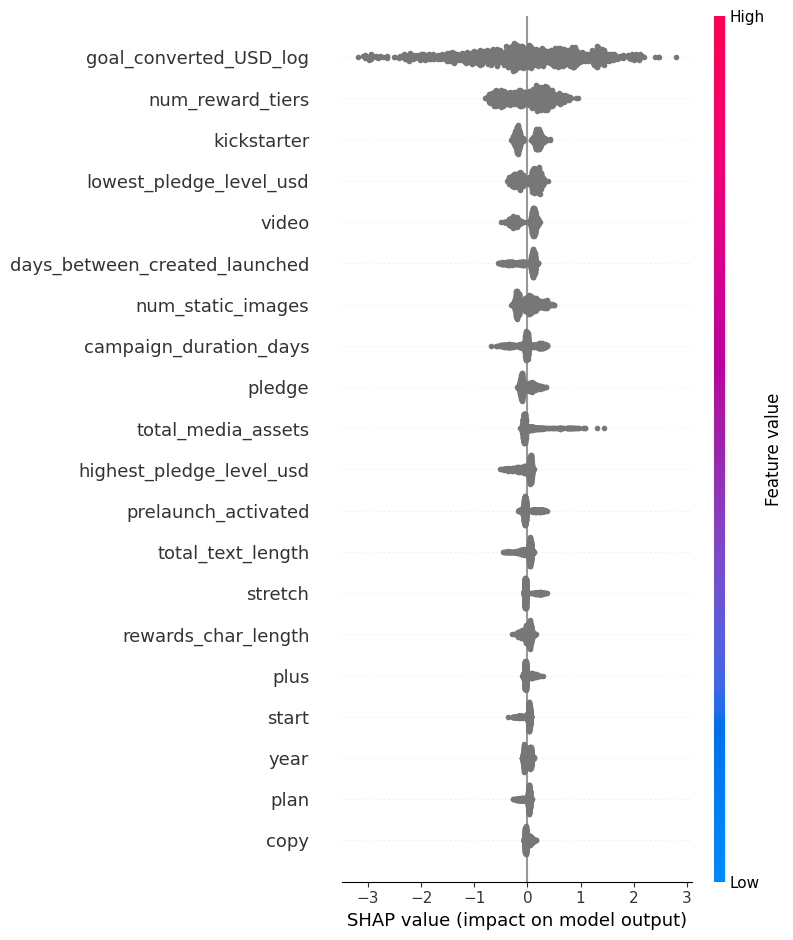

In [ ]:
# SHAP analysis for the structured TF-IDF XGBoost model
explainer = shap.TreeExplainer(xgb_model_tfidf)

# use subset
X_sample = X_train_combined_tfidf[:1000] 

shap_values = explainer.shap_values(X_sample)

if isinstance(shap_values, list):
    shap_values = shap_values[1]

# Create Importance DataFrame using the feature names
shap_df = pd.DataFrame(shap_values, columns=combined_feature_names_tfidf)
shap_importance_tfidf = shap_df.abs().mean().sort_values(ascending=False)

print("\nTop 10 features by SHAP:")
print(shap_importance_tfidf.head(10))

# Visualize
shap.summary_plot(shap_values, X_sample, feature_names=combined_feature_names_tfidf)

In [108]:
# BoW + metadata XGBoost
xgb_model_bow = train_xgboost2(
    X_train_combined_bow, X_val_combined_bow, X_test_combined_bow, 
    y_train_meta, y_val_meta, y_test_meta, 
    combined_feature_names_bow, 
    model_name="XGBoost (BoW + Metadata)"
)


Training XGBoost (BoW + Metadata) with RandomizedSearchCV...
Fitting 5 folds for each of 10 candidates, totalling 50 fits


[CV 1/5] END gamma=0, learning_rate=0.01, max_depth=5, min_child_weight=5, n_estimators=300;, score=0.869 total time=  36.4s
[CV 2/5] END gamma=0.2, learning_rate=0.01, max_depth=4, min_child_weight=5, n_estimators=500;, score=0.881 total time=  38.4s
[CV 3/5] END gamma=0, learning_rate=0.01, max_depth=5, min_child_weight=5, n_estimators=300;, score=0.874 total time=  38.2s
[CV 2/5] END gamma=0, learning_rate=0.01, max_depth=5, min_child_weight=5, n_estimators=300;, score=0.877 total time=  38.3s
[CV 4/5] END gamma=0.2, learning_rate=0.01, max_depth=4, min_child_weight=5, n_estimators=500;, score=0.873 total time=  38.7s
[CV 3/5] END gamma=0.2, learning_rate=0.01, max_depth=4, min_child_weight=5, n_estimators=500;, score=0.878 total time=  39.4s
[CV 1/5] END gamma=0.2, learning_rate=0.01, max_depth=4, min_child_weight=5, n_estimators=500;, score=0.873 total time=  41.0s
[CV 5/5] END gamma=0.2, learning_rate=0.01, max_depth=4, min_child_weight=5, n_estimators=500;, score=0.872 total tim

In [109]:
train_auc, test_auc = check_auc_overfitting(xgb_model_bow, X_train_combined_bow, X_test_combined_bow, y_train_meta, y_test_meta)

AUC OVERFITTING CHECK:
Train AUC: 0.9672
Test AUC:  0.8979
Difference: 0.0693


In [110]:
# BoW + metadata (structured) XGBoost
xgb_model_bow_structured = train_xgboost2(
    X_train_bow_combined_structured,
    X_val_bow_combined_structured,
    X_test_bow_combined_structured,
    y_train_meta,
    y_val_meta,
    y_test_meta,
    combined_feature_names_bow_structured,
    model_name="XGBoost (BoW + Metadata Structured)"
)


Training XGBoost (BoW + Metadata Structured) with RandomizedSearchCV...
Fitting 5 folds for each of 10 candidates, totalling 50 fits
[CV 3/5] END gamma=0, learning_rate=0.01, max_depth=5, min_child_weight=5, n_estimators=300;, score=0.873 total time=  36.8s
[CV 2/5] END gamma=0, learning_rate=0.01, max_depth=5, min_child_weight=5, n_estimators=300;, score=0.875 total time=  38.6s
[CV 1/5] END gamma=0, learning_rate=0.01, max_depth=5, min_child_weight=5, n_estimators=300;, score=0.868 total time=  39.0s
[CV 4/5] END gamma=0.2, learning_rate=0.01, max_depth=4, min_child_weight=5, n_estimators=500;, score=0.870 total time=  40.3s
[CV 2/5] END gamma=0.2, learning_rate=0.01, max_depth=4, min_child_weight=5, n_estimators=500;, score=0.879 total time=  40.4s
[CV 1/5] END gamma=0.2, learning_rate=0.01, max_depth=4, min_child_weight=5, n_estimators=500;, score=0.872 total time=  40.5s
[CV 5/5] END gamma=0.2, learning_rate=0.01, max_depth=4, min_child_weight=5, n_estimators=500;, score=0.871 to

In [111]:
# check auc overfitting
train_auc, test_auc = check_auc_overfitting(xgb_model_bow_structured, X_train_bow_combined_structured, X_test_bow_combined_structured, y_train_meta, y_test_meta)

AUC OVERFITTING CHECK:
Train AUC: 0.9880
Test AUC:  0.8981
Difference: 0.0899


In [112]:
# bert + metadata XGBoost
xgb_model_bert = train_xgboost2(
    X_train_combined_bert, X_val_combined_bert, X_test_combined_bert, 
    y_train_meta, y_val_meta, y_test_meta, 
    combined_feature_names_bert, 
    model_name="XGBoost (BERT + Metadata)"
)


Training XGBoost (BERT + Metadata) with RandomizedSearchCV...
Fitting 5 folds for each of 10 candidates, totalling 50 fits


[CV 1/5] END gamma=0, learning_rate=0.01, max_depth=5, min_child_weight=5, n_estimators=300;, score=0.863 total time=  57.5s
[CV 3/5] END gamma=0, learning_rate=0.01, max_depth=5, min_child_weight=5, n_estimators=300;, score=0.866 total time=  58.0s
[CV 2/5] END gamma=0, learning_rate=0.01, max_depth=5, min_child_weight=5, n_estimators=300;, score=0.872 total time=  59.1s
[CV 3/5] END gamma=0.2, learning_rate=0.01, max_depth=4, min_child_weight=5, n_estimators=500;, score=0.871 total time=  60.0s
[CV 2/5] END gamma=0.2, learning_rate=0.01, max_depth=4, min_child_weight=5, n_estimators=500;, score=0.875 total time= 1.0min
[CV 4/5] END gamma=0.2, learning_rate=0.01, max_depth=4, min_child_weight=5, n_estimators=500;, score=0.866 total time= 1.0min
[CV 1/5] END gamma=0.2, learning_rate=0.01, max_depth=4, min_child_weight=5, n_estimators=500;, score=0.867 total time= 1.1min
[CV 5/5] END gamma=0.2, learning_rate=0.01, max_depth=4, min_child_weight=5, n_estimators=500;, score=0.866 total tim

In [113]:
# check auc overfitting
train_auc, test_auc = check_auc_overfitting(xgb_model_bert, X_train_combined_bert, X_test_combined_bert, y_train_meta, y_test_meta)

AUC OVERFITTING CHECK:
Train AUC: 0.9818
Test AUC:  0.8857
Difference: 0.0962


In [114]:
# BERT + metadata (structured) XGBoost
xgb_model_bert_structured = train_xgboost2(
    X_train_bert_combined_structured,
    X_val_bert_combined_structured,
    X_test_bert_combined_structured,
    y_train_meta,
    y_val_meta,
    y_test_meta,
    combined_feature_names_bert_structured,
    model_name="XGBoost (BERT + Metadata Structured)"
)


Training XGBoost (BERT + Metadata Structured) with RandomizedSearchCV...
Fitting 5 folds for each of 10 candidates, totalling 50 fits


[CV 3/5] END gamma=0, learning_rate=0.01, max_depth=5, min_child_weight=5, n_estimators=300;, score=0.873 total time= 6.3min
[CV 4/5] END gamma=0.2, learning_rate=0.01, max_depth=4, min_child_weight=5, n_estimators=500;, score=0.871 total time= 7.8min
[CV 2/5] END gamma=0.2, learning_rate=0.01, max_depth=4, min_child_weight=5, n_estimators=500;, score=0.878 total time= 8.1min
[CV 2/5] END gamma=0, learning_rate=0.01, max_depth=5, min_child_weight=5, n_estimators=300;, score=0.874 total time= 8.2min
[CV 1/5] END gamma=0, learning_rate=0.01, max_depth=5, min_child_weight=5, n_estimators=300;, score=0.867 total time= 8.7min
[CV 3/5] END gamma=0.2, learning_rate=0.01, max_depth=4, min_child_weight=5, n_estimators=500;, score=0.877 total time= 9.4min
[CV 5/5] END gamma=0.2, learning_rate=0.01, max_depth=4, min_child_weight=5, n_estimators=500;, score=0.871 total time= 9.7min
[CV 1/5] END gamma=0.2, learning_rate=0.01, max_depth=4, min_child_weight=5, n_estimators=500;, score=0.872 total tim

/home/ucloud/.local/lib/python3.12/site-packages/joblib/externals/loky/process_executor.py:782: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


[CV 4/5] END gamma=0, learning_rate=0.01, max_depth=5, min_child_weight=5, n_estimators=300;, score=0.867 total time= 7.8min
[CV 4/5] END gamma=0, learning_rate=0.01, max_depth=4, min_child_weight=5, n_estimators=300;, score=0.860 total time= 5.1min
[CV 5/5] END gamma=0, learning_rate=0.01, max_depth=5, min_child_weight=5, n_estimators=300;, score=0.866 total time= 6.8min
[CV 3/5] END gamma=0, learning_rate=0.01, max_depth=4, min_child_weight=5, n_estimators=300;, score=0.866 total time= 6.2min
[CV 5/5] END gamma=0, learning_rate=0.01, max_depth=4, min_child_weight=5, n_estimators=300;, score=0.859 total time= 5.6min
[CV 1/5] END gamma=0.1, learning_rate=0.1, max_depth=4, min_child_weight=3, n_estimators=300;, score=0.890 total time= 4.6min
[CV 3/5] END gamma=0.1, learning_rate=0.1, max_depth=4, min_child_weight=3, n_estimators=300;, score=0.888 total time= 5.2min
[CV 2/5] END gamma=0.1, learning_rate=0.1, max_depth=4, min_child_weight=3, n_estimators=300;, score=0.891 total time= 5.8m

In [115]:
# check auc overfitting
train_auc, test_auc = check_auc_overfitting(xgb_model_bert_structured, X_train_bert_combined_structured, X_test_bert_combined_structured, y_train_meta, y_test_meta)

AUC OVERFITTING CHECK:
Train AUC: 0.9931
Test AUC:  0.8903
Difference: 0.1028


In [23]:
# fine tuned BERT + meta
xgb_model_bert_ft = train_xgboost2(
    X_train_combined_bert_ft, X_val_combined_bert_ft, X_test_combined_bert_ft, 
    y_train_meta, y_val_meta, y_test_meta, 
    combined_feature_names_bert_ft, 
    model_name="XGBoost (fine-tuned BERT + Metadata)"
)


Training XGBoost (fine-tuned BERT + Metadata) with RandomizedSearchCV...
Fitting 5 folds for each of 10 candidates, totalling 50 fits


[CV 1/5] END gamma=0, learning_rate=0.01, max_depth=5, min_child_weight=5, n_estimators=300;, score=0.931 total time=  18.2s
[CV 2/5] END gamma=0, learning_rate=0.01, max_depth=5, min_child_weight=5, n_estimators=300;, score=0.932 total time=  19.3s
[CV 3/5] END gamma=0, learning_rate=0.01, max_depth=5, min_child_weight=5, n_estimators=300;, score=0.923 total time=  20.1s
[CV 1/5] END gamma=0.2, learning_rate=0.01, max_depth=4, min_child_weight=5, n_estimators=500;, score=0.933 total time=  20.5s
[CV 4/5] END gamma=0.2, learning_rate=0.01, max_depth=4, min_child_weight=5, n_estimators=500;, score=0.932 total time=  22.2s
[CV 2/5] END gamma=0.2, learning_rate=0.01, max_depth=4, min_child_weight=5, n_estimators=500;, score=0.934 total time=  22.3s
[CV 3/5] END gamma=0.2, learning_rate=0.01, max_depth=4, min_child_weight=5, n_estimators=500;, score=0.926 total time=  23.3s
[CV 5/5] END gamma=0.2, learning_rate=0.01, max_depth=4, min_child_weight=5, n_estimators=500;, score=0.933 total tim

In [24]:
# check auc overfitting
train_auc, test_auc = check_auc_overfitting(xgb_model_bert_ft, X_train_combined_bert_ft, X_test_combined_bert_ft, y_train_meta, y_test_meta)

AUC OVERFITTING CHECK:
Train AUC: 0.9684
Test AUC:  0.8911
Difference: 0.0773


In [25]:
# Fine-tuned BERT + metadata (structured) XGBoost
xgb_model_bert_ft_structured = train_xgboost2(
    X_train_combined_bert_ft_structured,
    X_val_combined_bert_ft_structured,
    X_test_combined_bert_ft_structured,
    y_train_meta,
    y_val_meta,
    y_test_meta,
    combined_feature_names_bert_ft_structured,
    model_name="XGBoost (BERT FT + Metadata Structured)"
)


Training XGBoost (BERT FT + Metadata Structured) with RandomizedSearchCV...
Fitting 5 folds for each of 10 candidates, totalling 50 fits
[CV 1/5] END gamma=0, learning_rate=0.01, max_depth=5, min_child_weight=5, n_estimators=300;, score=0.914 total time= 1.9min
[CV 3/5] END gamma=0.2, learning_rate=0.01, max_depth=4, min_child_weight=5, n_estimators=500;, score=0.911 total time= 1.9min
[CV 5/5] END gamma=0.2, learning_rate=0.01, max_depth=4, min_child_weight=5, n_estimators=500;, score=0.916 total time= 1.9min
[CV 2/5] END gamma=0, learning_rate=0.01, max_depth=5, min_child_weight=5, n_estimators=300;, score=0.917 total time= 1.9min
[CV 3/5] END gamma=0, learning_rate=0.01, max_depth=5, min_child_weight=5, n_estimators=300;, score=0.907 total time= 1.9min
[CV 4/5] END gamma=0.2, learning_rate=0.01, max_depth=4, min_child_weight=5, n_estimators=500;, score=0.915 total time= 2.1min
[CV 1/5] END gamma=0.2, learning_rate=0.01, max_depth=4, min_child_weight=5, n_estimators=500;, score=0.91

In [26]:
# check auc overfitting
train_auc, test_auc = check_auc_overfitting(xgb_model_bert_ft_structured, X_train_combined_bert_ft_structured, X_test_combined_bert_ft_structured, y_train_meta, y_test_meta)

AUC OVERFITTING CHECK:
Train AUC: 0.9763
Test AUC:  0.8971
Difference: 0.0792


Deep learning models

In [ ]:
# simple concatenation fusion
# define inputs for metadata and text branches
X_meta_train = X_train_meta_dense
X_meta_val   = X_val_meta_dense
X_meta_test  = X_test_meta_dense

X_text_train = X_train_bert_ft
X_text_val   = X_val_bert_ft
X_text_test  = X_test_bert_ft

y_train_nn = y_train_meta
y_val_nn   = y_val_meta
y_test_nn  = y_test_meta

# Input Dimensions
meta_dim = X_meta_train.shape[1]
text_dim = X_text_train.shape[1]

# Metadata Encoder Branch
meta_input = Input(shape=(meta_dim,), name="meta_input")

m = Dense(128, activation='relu', kernel_regularizer=l2(1e-5))(meta_input)
m = BatchNormalization()(m)
m = Dropout(0.4)(m)

m = Dense(32, activation='relu', kernel_regularizer=l2(1e-5))(m)
m = BatchNormalization()(m)
meta_repr = Dropout(0.3)(m)

# Text Encoder Branch
text_input = Input(shape=(text_dim,), name="text_input")

t = Dense(256, activation='relu', kernel_regularizer=l2(1e-5))(text_input)
t = BatchNormalization()(t)
t = Dropout(0.4)(t)

t = Dense(64, activation='relu', kernel_regularizer=l2(1e-5))(t)
t = BatchNormalization()(t)
text_repr = Dropout(0.3)(t)

# Fusion Layer (Concatenation Fusion)
fusion = Concatenate()([meta_repr, text_repr])

z = Dense(64, activation='relu', kernel_regularizer=l2(1e-5))(fusion)
z = BatchNormalization()(z)
z = Dropout(0.4)(z)

output = Dense(1, activation='sigmoid')(z)

# Model Compile
model = Model(inputs=[meta_input, text_input], outputs=output)

model.compile(
    optimizer=Adam(learning_rate=1e-4),
    loss=tf.keras.losses.BinaryCrossentropy(label_smoothing=0.05),
    metrics=[
        "accuracy",
        tf.keras.metrics.AUC(name="auc")
    ]
)

# Callbacks
early_stop = EarlyStopping(
    monitor='val_auc',
    mode='max',
    patience=15,
    restore_best_weights=True,
    verbose=1
)

lr_scheduler = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=5,
    min_lr=1e-6,
    verbose=1
)

# Training
history = model.fit(
    [X_meta_train, X_text_train],
    y_train_nn,
    validation_data=(
        [X_meta_val, X_text_val],
        y_val_nn
    ),
    epochs=100,
    batch_size=64,
    callbacks=[early_stop, lr_scheduler],
    verbose=2
)

# Evaluation
results = model.evaluate(
    [X_meta_test, X_text_test],
    y_test_nn,
    verbose=0
)

print(f"\nTest Loss: {results[0]:.4f}")
print(f"Test Accuracy: {results[1]:.4f}")
print(f"Test AUC: {results[2]:.4f}")

Epoch 1/100


441/441 - 7s - 15ms/step - accuracy: 0.7794 - auc: 0.8557 - loss: 0.5401 - val_accuracy: 0.7793 - val_auc: 0.8673 - val_loss: 0.5111 - learning_rate: 1.0000e-04
Epoch 2/100
441/441 - 3s - 7ms/step - accuracy: 0.8142 - auc: 0.8886 - loss: 0.4810 - val_accuracy: 0.7826 - val_auc: 0.8700 - val_loss: 0.5169 - learning_rate: 1.0000e-04
Epoch 3/100
441/441 - 3s - 7ms/step - accuracy: 0.8189 - auc: 0.8953 - loss: 0.4644 - val_accuracy: 0.7861 - val_auc: 0.8733 - val_loss: 0.5030 - learning_rate: 1.0000e-04
Epoch 4/100
441/441 - 3s - 7ms/step - accuracy: 0.8277 - auc: 0.9012 - loss: 0.4507 - val_accuracy: 0.7863 - val_auc: 0.8758 - val_loss: 0.4976 - learning_rate: 1.0000e-04
Epoch 5/100
441/441 - 3s - 7ms/step - accuracy: 0.8290 - auc: 0.9036 - loss: 0.4447 - val_accuracy: 0.7888 - val_auc: 0.8785 - val_loss: 0.4882 - learning_rate: 1.0000e-04
Epoch 6/100
441/441 - 3s - 7ms/step - accuracy: 0.8346 - auc: 0.9088 - loss: 0.4337 - val_accuracy: 0.7934 - val_auc: 0.8813 - val_loss: 0.4847 - learn

In [35]:
# Predict probabilities on test set
y_pred_proba = model.predict([X_meta_test, X_text_test])

# Convert probabilities to binary predictions (threshold=0.5)
y_pred = (y_pred_proba >= 0.5).astype(int).flatten()

# Compute precision, recall, F1
precision = precision_score(y_test_nn, y_pred)
recall = recall_score(y_test_nn, y_pred)
f1 = f1_score(y_test_nn, y_pred)

print(f"\nTest Precision: {precision:.4f}")
print(f"Test Recall:    {recall:.4f}")
print(f"Test F1-score:  {f1:.4f}")

# Full classification report
print("\nClassification Report:")
print(classification_report(y_test_nn, y_pred))

142/189 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step

189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step

Test Precision: 0.7975
Test Recall:    0.8184
Test F1-score:  0.8078

Classification Report:
              precision    recall  f1-score   support

           0       0.81      0.78      0.79      2962
           1       0.80      0.82      0.81      3084

    accuracy                           0.80      6046
   macro avg       0.80      0.80      0.80      6046
weighted avg       0.80      0.80      0.80      6046



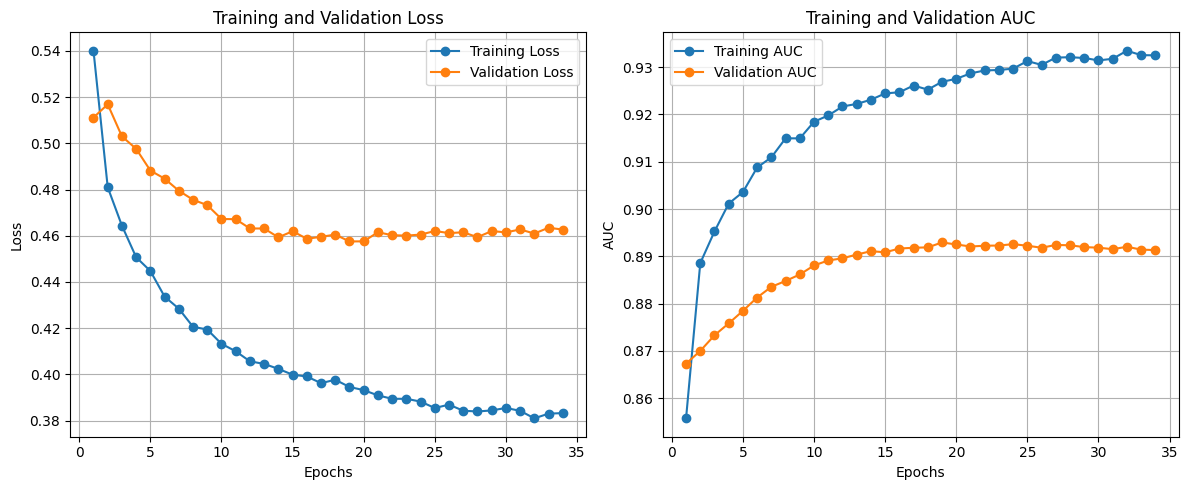

In [ ]:
# Extract metrics
loss = history.history['loss']
val_loss = history.history['val_loss']
auc = history.history['auc']
val_auc = history.history['val_auc']

epochs = range(1, len(loss)+1)

# Plot Loss
plt.figure(figsize=(12,5))

plt.subplot(1,2,1)
plt.plot(epochs, loss, label='Training Loss', marker='o')
plt.plot(epochs, val_loss, label='Validation Loss', marker='o')
plt.title('Training and Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

# Plot AUC
plt.subplot(1,2,2)
plt.plot(epochs, auc, label='Training AUC', marker='o')
plt.plot(epochs, val_auc, label='Validation AUC', marker='o')
plt.title('Training and Validation AUC')
plt.xlabel('Epochs')
plt.ylabel('AUC')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

In [ ]:
# deep fusion MLP 
# Define inputs
X_meta_train = X_train_meta_dense
X_meta_val   = X_val_meta_dense
X_meta_test  = X_test_meta_dense

X_text_train = X_train_bert_ft
X_text_val   = X_val_bert_ft
X_text_test  = X_test_bert_ft

y_train_nn = y_train_meta
y_val_nn   = y_val_meta
y_test_nn  = y_test_meta

# Dimensions
meta_dim = X_meta_train.shape[1]
text_dim = X_text_train.shape[1]

# Metadata Encoder Branch
meta_input = Input(shape=(meta_dim,), name="meta_input")
m = Dense(128, activation='swish', kernel_regularizer=l2(2e-5))(meta_input)
m = BatchNormalization()(m)
m = Dropout(0.4)(m)
meta_repr = Dense(64, activation='swish')(m)

# Text Encoder Branch
text_input = Input(shape=(text_dim,), name="text_input")
t = Dense(256, activation='swish', kernel_regularizer=l2(2e-5))(text_input)
t = BatchNormalization()(t)
t = Dropout(0.4)(t)
text_repr = Dense(128, activation='swish')(t)

# Fusion Block
fusion = Concatenate()([meta_repr, text_repr])

z = Dense(256, activation='swish')(fusion)
z = BatchNormalization()(z)
z = Dropout(0.5)(z)

z = Dense(64, activation='swish')(z)
z = BatchNormalization()(z)

# Final decision head
output = Dense(1, activation='sigmoid')(z)

# Model Definition
model = Model(inputs=[meta_input, text_input], outputs=output)

# Compilation
model.compile(
    optimizer=Adam(learning_rate=1e-4),
    loss=tf.keras.losses.BinaryCrossentropy(label_smoothing=0.02),
    metrics=[
        "accuracy",
        tf.keras.metrics.AUC(name="auc")
    ]
)

model.summary()

# Callbacks
early_stop = EarlyStopping(
    monitor='val_auc',
    mode='max',
    patience=10,
    restore_best_weights=True,
    verbose=1
)

lr_scheduler = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=4,
    min_lr=1e-6,
    verbose=1
)

# Training
history = model.fit(
    [X_meta_train, X_text_train],
    y_train_nn,
    validation_data=(
        [X_meta_val, X_text_val],
        y_val_nn
    ),
    epochs=100,
    batch_size=64,
    callbacks=[early_stop, lr_scheduler],
    verbose=2
)

# Evaluation
results = model.evaluate(
    [X_meta_test, X_text_test],
    y_test_nn,
    verbose=0
)

print(f"\nTest Loss: {results[0]:.4f}")
print(f"Test Accuracy: {results[1]:.4f}")
print(f"Test AUC: {results[2]:.4f}")

Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ meta_input          │ (None, 91)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ text_input          │ (None, 256)       │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_9 (Dense)     │ (None, 128)       │     11,776 │ meta_input[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_11 (Dense)    │ (None, 256)       │     65,792 │ text_input[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128)       │        512 │ dense_9[0][0]     │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 256)       │      1,024 │ dense_11[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_7 (Dropout) │ (None, 128)       │          0 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_8 (Dropout) │ (None, 256)       │          0 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_10 (Dense)    │ (None, 64)        │      8,256 │ dropout_7[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_12 (Dense)    │ (None, 128)       │     32,896 │ dropout_8[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_1       │ (None, 192)       │          0 │ dense_10[0][0],   │
│ (Concatenate)       │                   │            │ dense_12[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_13 (Dense)    │ (None, 256)       │     49,408 │ concatenate_1[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 256)       │      1,024 │ dense_13[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_9 (Dropout) │ (None, 256)       │          0 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_14 (Dense)    │ (None, 64)        │     16,448 │ dropout_9[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 64)        │        256 │ dense_14[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_15 (Dense)    │ (None, 1)         │         65 │ batch_normalizat… │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 187,457 (732.25 KB)

 Trainable params: 186,049 (726.75 KB)

 Non-trainable params: 1,408 (5.50 KB)

Epoch 1/100
441/441 - 7s - 17ms/step - accuracy: 0.8166 - auc: 0.8920 - loss: 0.4472 - val_accuracy: 0.7840 - val_auc: 0.8811 - val_loss: 0.4757 - learning_rate: 1.0000e-04
Epoch 2/100
441/441 - 4s - 8ms/step - accuracy: 0.8353 - auc: 0.9112 - loss: 0.4049 - val_accuracy: 0.7942 - val_auc: 0.8836 - val_loss: 0.4722 - learning_rate: 1.0000e-04
Epoch 3/100
441/441 - 4s - 8ms/step - accuracy: 0.8440 - auc: 0.9171 - loss: 0.3921 - val_accuracy: 0.8012 - val_auc: 0.8873 - val_loss: 0.4587 - learning_rate: 1.0000e-04
Epoch 4/100
441/441 - 4s - 8ms/step - accuracy: 0.8461 - auc: 0.9196 - loss: 0.3854 - val_accuracy: 0.8035 - val_auc: 0.8880 - val_loss: 0.4586 - learning_rate: 1.0000e-04
Epoch 5/100
441/441 - 4s - 8ms/step - accuracy: 0.8502 - auc: 0.9231 - loss: 0.3779 - val_accuracy: 0.8074 - val_auc: 0.8906 - val_loss: 0.4475 - learning_rate: 1.0000e-04
Epoch 6/100
441/441 - 4s - 8ms/step - accuracy: 0.8486 - auc: 0.9239 - loss: 0.3758 - val_accuracy: 0.8071 - val_auc: 0.8918 - val_loss: 0.

In [38]:
# Predict probabilities on test set
y_pred_proba = model.predict([X_meta_test, X_text_test])

# Convert probabilities to binary predictions (threshold=0.5)
y_pred = (y_pred_proba >= 0.5).astype(int).flatten()

# Compute precision, recall, F1
precision = precision_score(y_test_nn, y_pred)
recall = recall_score(y_test_nn, y_pred)
f1 = f1_score(y_test_nn, y_pred)

print(f"\nTest Precision: {precision:.4f}")
print(f"Test Recall:    {recall:.4f}")
print(f"Test F1-score:  {f1:.4f}")

# Full classification report
print("\nClassification Report:")
print(classification_report(y_test_nn, y_pred))

189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step

Test Precision: 0.7841
Test Recall:    0.8515
Test F1-score:  0.8164

Classification Report:
              precision    recall  f1-score   support

           0       0.83      0.76      0.79      2962
           1       0.78      0.85      0.82      3084

    accuracy                           0.80      6046
   macro avg       0.81      0.80      0.80      6046
weighted avg       0.81      0.80      0.80      6046



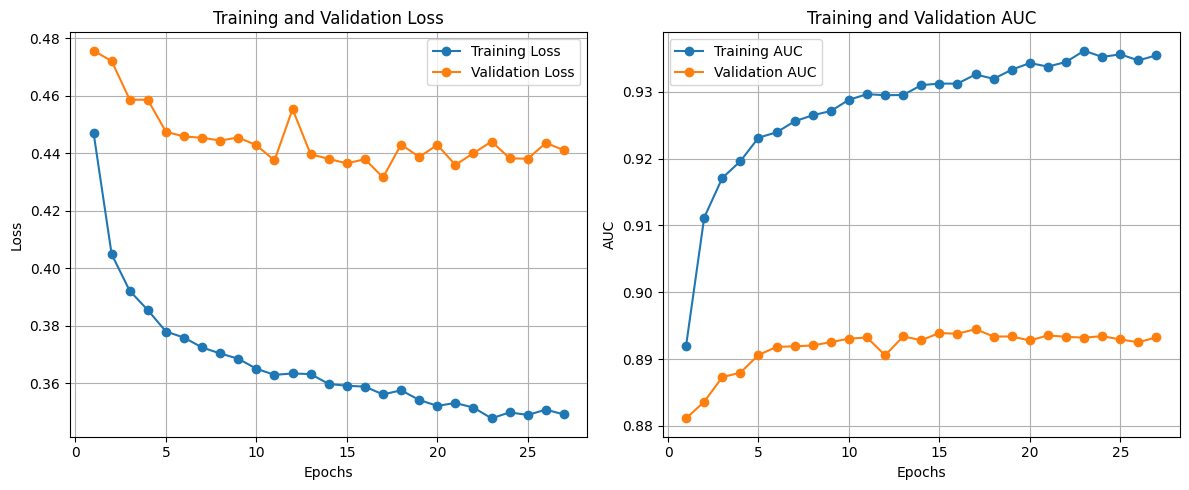

In [ ]:
# Extract metrics
loss = history.history['loss']
val_loss = history.history['val_loss']
auc = history.history['auc']
val_auc = history.history['val_auc']

epochs = range(1, len(loss)+1)

# Plot Loss
plt.figure(figsize=(12,5))

plt.subplot(1,2,1)
plt.plot(epochs, loss, label='Training Loss', marker='o')
plt.plot(epochs, val_loss, label='Validation Loss', marker='o')
plt.title('Training and Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

# Plot AUC
plt.subplot(1,2,2)
plt.plot(epochs, auc, label='Training AUC', marker='o')
plt.plot(epochs, val_auc, label='Validation AUC', marker='o')
plt.title('Training and Validation AUC')
plt.xlabel('Epochs')
plt.ylabel('AUC')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

In [ ]:
# Custom callback to monitor gate weights during training
class GateMonitor(Callback):
    def on_epoch_end(self, epoch, logs=None):
        # sub-model to extract gate weights
        gate_layer_model = Model(inputs=self.model.input, 
                                 outputs=self.model.get_layer("gate_weight").output)
        # Predict on a small sample of validation data
        sample_indices = np.random.choice(len(X_meta_val), 100, replace=False)
        weights = gate_layer_model.predict([X_meta_val[sample_indices], X_text_val[sample_indices]], verbose=0)
        avg_weight = np.mean(weights)
        print(f" — Avg Gate Weight (Text Importance): {avg_weight:.4f}")

# Input Dimensions
meta_dim = X_meta_train.shape[1]
text_dim = X_text_train.shape[1]

# Metadata Encoder Branch
meta_input = Input(shape=(meta_dim,), name="meta_input")
m = Dense(128, activation='swish', kernel_regularizer=l2(1e-5))(meta_input)
m = BatchNormalization()(m)
m = Dropout(0.4)(m)
meta_repr = Dense(64, activation='swish')(m)

# Text Encoder Branch
text_input = Input(shape=(text_dim,), name="text_input")
t = Dense(256, activation='swish', kernel_regularizer=l2(1e-5))(text_input)
t = BatchNormalization()(t)
t = Dropout(0.4)(t)
text_repr = Dense(128, activation='swish')(t)

# Gated Fusion Block
# Determine the gate importance based on both inputs
gate_features = Concatenate()([meta_repr, text_repr])
gate_weight = Dense(64, activation='swish')(gate_features)
# gate_weight close to 1.0 = Text focus | close to 0.0 = Meta focus
gate_weight = Dense(1, activation='sigmoid', name="gate_weight")(gate_weight)

# Apply Weights
weighted_text = Multiply()([text_repr, gate_weight])
inverse_gate = Lambda(lambda x: 1.0 - x)(gate_weight)
weighted_meta = Multiply()([meta_repr, inverse_gate])

# Combine weighted features
fusion = Concatenate()([weighted_text, weighted_meta])

# Decision Head (Diamond MLP)
z = Dense(128, activation='swish', kernel_regularizer=l2(1e-5))(fusion)
z = BatchNormalization()(z)
z = Dropout(0.4)(z)

z = Dense(64, activation='swish', kernel_regularizer=l2(1e-5))(z)
z = BatchNormalization()(z)

output = Dense(1, activation='sigmoid')(z)

# Compile and Train
model = Model(inputs=[meta_input, text_input], outputs=output)

model.compile(
    optimizer=Adam(learning_rate=1e-4),
    loss=tf.keras.losses.BinaryCrossentropy(label_smoothing=0.02),
    metrics=["accuracy", tf.keras.metrics.AUC(name="auc")]
)

early_stop = EarlyStopping(
    monitor='val_auc', mode='max', patience=12, restore_best_weights=True, verbose=1
)

lr_scheduler = ReduceLROnPlateau(
    monitor='val_loss', factor=0.5, patience=5, min_lr=1e-6, verbose=1
)

history = model.fit(
    [X_meta_train, X_text_train],
    y_train_nn,
    validation_data=([X_meta_val, X_text_val], y_val_nn),
    epochs=100,
    batch_size=64,
    callbacks=[early_stop, lr_scheduler, GateMonitor()],
    verbose=2
)

# Final Evaluation
results = model.evaluate([X_meta_test, X_text_test], y_test_nn, verbose=0)
print(f"\nFinal Test Loss: {results[0]:.4f}")
print(f"Final Test Accuracy: {results[1]:.4f}")
print(f"Final Test AUC: {results[2]:.4f}")

Epoch 1/100
 — Avg Gate Weight (Text Importance): 0.6010
441/441 - 8s - 19ms/step - accuracy: 0.8099 - auc: 0.8865 - loss: 0.4586 - val_accuracy: 0.7782 - val_auc: 0.8750 - val_loss: 0.4815 - learning_rate: 1.0000e-04
Epoch 2/100
 — Avg Gate Weight (Text Importance): 0.5383
441/441 - 4s - 9ms/step - accuracy: 0.8359 - auc: 0.9098 - loss: 0.4075 - val_accuracy: 0.8026 - val_auc: 0.8823 - val_loss: 0.4663 - learning_rate: 1.0000e-04
Epoch 3/100
 — Avg Gate Weight (Text Importance): 0.5644
441/441 - 4s - 9ms/step - accuracy: 0.8400 - auc: 0.9161 - loss: 0.3933 - val_accuracy: 0.8063 - val_auc: 0.8873 - val_loss: 0.4566 - learning_rate: 1.0000e-04
Epoch 4/100
 — Avg Gate Weight (Text Importance): 0.5422
441/441 - 4s - 9ms/step - accuracy: 0.8428 - auc: 0.9198 - loss: 0.3847 - val_accuracy: 0.8106 - val_auc: 0.8910 - val_loss: 0.4478 - learning_rate: 1.0000e-04
Epoch 5/100
 — Avg Gate Weight (Text Importance): 0.5564
441/441 - 4s - 10ms/step - accuracy: 0.8475 - auc: 0.9214 - loss: 0.3811 -

In [41]:
# Predict probabilities on test set
y_pred_proba = model.predict([X_meta_test, X_text_test])

# Convert probabilities to binary predictions (threshold=0.5)
y_pred = (y_pred_proba >= 0.5).astype(int).flatten()

# Compute precision, recall, F1
precision = precision_score(y_test_nn, y_pred)
recall = recall_score(y_test_nn, y_pred)
f1 = f1_score(y_test_nn, y_pred)

print(f"\nTest Precision: {precision:.4f}")
print(f"Test Recall:    {recall:.4f}")
print(f"Test F1-score:  {f1:.4f}")

# Full classification report
print("\nClassification Report:")
print(classification_report(y_test_nn, y_pred))

189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step

Test Precision: 0.7873
Test Recall:    0.8534
Test F1-score:  0.8190

Classification Report:
              precision    recall  f1-score   support

           0       0.83      0.76      0.79      2962
           1       0.79      0.85      0.82      3084

    accuracy                           0.81      6046
   macro avg       0.81      0.81      0.81      6046
weighted avg       0.81      0.81      0.81      6046



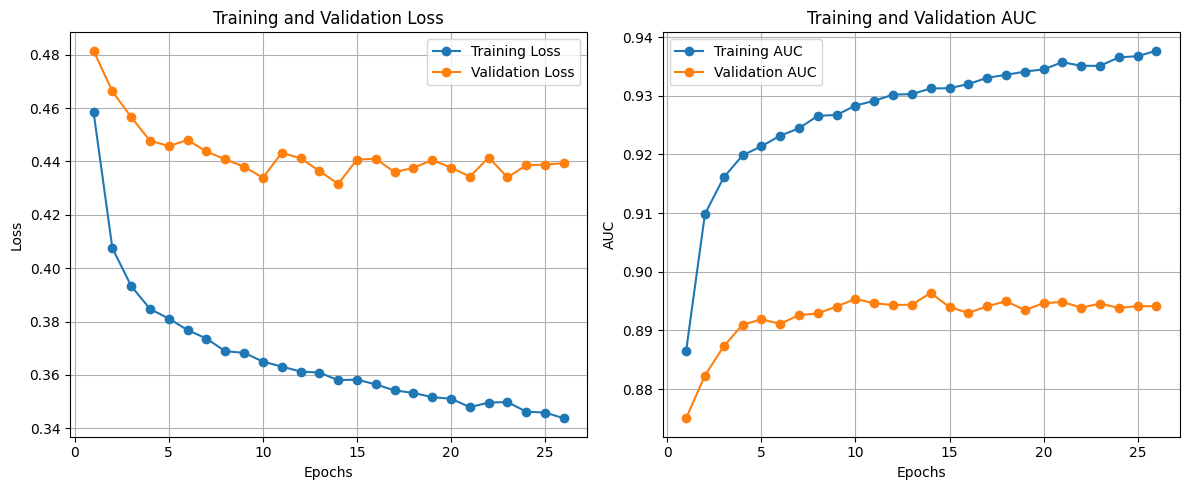

In [ ]:
# Extract metrics
loss = history.history['loss']
val_loss = history.history['val_loss']
auc = history.history['auc']
val_auc = history.history['val_auc']

epochs = range(1, len(loss)+1)

# Plot Loss
plt.figure(figsize=(12,5))

plt.subplot(1,2,1)
plt.plot(epochs, loss, label='Training Loss', marker='o')
plt.plot(epochs, val_loss, label='Validation Loss', marker='o')
plt.title('Training and Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

# Plot AUC
plt.subplot(1,2,2)
plt.plot(epochs, auc, label='Training AUC', marker='o')
plt.plot(epochs, val_auc, label='Validation AUC', marker='o')
plt.title('Training and Validation AUC')
plt.xlabel('Epochs')
plt.ylabel('AUC')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

In [ ]:
# deep fusion MLP (cross-interaction)
# Define inputs
X_meta_train = X_train_meta_dense
X_meta_val   = X_val_meta_dense
X_meta_test  = X_test_meta_dense

X_text_train = X_train_bert_ft
X_text_val   = X_val_bert_ft
X_text_test  = X_test_bert_ft

y_train_nn = y_train_meta
y_val_nn   = y_val_meta
y_test_nn  = y_test_meta

# Dimensions
meta_dim = X_meta_train.shape[1]
text_dim = X_text_train.shape[1]

# Metadata Encoder Branch
meta_input = Input(shape=(meta_dim,), name="meta_input")

m = Dense(128, activation='relu', kernel_regularizer=l2(1e-5))(meta_input)
m = BatchNormalization()(m)
m = Dropout(0.35)(m)

m = Dense(32, activation='relu', kernel_regularizer=l2(1e-5))(m)
m = BatchNormalization()(m)
meta_repr = Dropout(0.25)(m)

# Text Encoder Branch
text_input = Input(shape=(text_dim,), name="text_input")

t = Dense(256, activation='relu', kernel_regularizer=l2(1e-5))(text_input)
t = BatchNormalization()(t)
t = Dropout(0.35)(t)

t = Dense(128, activation='relu', kernel_regularizer=l2(1e-5))(t)
t = BatchNormalization()(t)
text_repr = Dropout(0.25)(t)

# Fusion Block (Cross-Interaction Style)
fusion = Concatenate()([meta_repr, text_repr])

# Interaction projection layer
z = Dense(
    128,
    activation='relu',
    kernel_regularizer=l2(1e-5)
)(fusion)
z = BatchNormalization()(z)
z = Dropout(0.3)(z)

# Feature interaction refinement
z = Dense(
    64,
    activation='relu',
    kernel_regularizer=l2(1e-5)
)(z)
z = BatchNormalization()(z)
z = Dropout(0.25)(z)

# Final decision head
output = Dense(1, activation='sigmoid')(z)

# Model Definition
model = Model(inputs=[meta_input, text_input], outputs=output)

# Compilation
model.compile(
    optimizer=Adam(learning_rate=2e-4),
    loss=tf.keras.losses.BinaryCrossentropy(label_smoothing=0.05),
    metrics=[
        "accuracy",
        tf.keras.metrics.AUC(name="auc")
    ]
)

model.summary()

# Callbacks
early_stop = EarlyStopping(
    monitor='val_auc',
    mode='max',
    patience=10,
    restore_best_weights=True,
    verbose=1
)

lr_scheduler = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=4,
    min_lr=1e-6,
    verbose=1
)

# Training
history = model.fit(
    [X_meta_train, X_text_train],
    y_train_nn,
    validation_data=(
        [X_meta_val, X_text_val],
        y_val_nn
    ),
    epochs=100,
    batch_size=64,
    callbacks=[early_stop, lr_scheduler],
    verbose=2
)

# Evaluation
results = model.evaluate(
    [X_meta_test, X_text_test],
    y_test_nn,
    verbose=0
)

print(f"\nTest Loss: {results[0]:.4f}")
print(f"Test Accuracy: {results[1]:.4f}")
print(f"Test AUC: {results[2]:.4f}")

Model: "functional_30"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ meta_input          │ (None, 91)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ text_input          │ (None, 256)       │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_24 (Dense)    │ (None, 128)       │     11,776 │ meta_input[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_26 (Dense)    │ (None, 256)       │     65,792 │ text_input[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128)       │        512 │ dense_24[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 256)       │      1,024 │ dense_26[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_13          │ (None, 128)       │          0 │ batch_normalizat… │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_15          │ (None, 256)       │          0 │ batch_normalizat… │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_25 (Dense)    │ (None, 32)        │      4,128 │ dropout_13[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_27 (Dense)    │ (None, 128)       │     32,896 │ dropout_15[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 32)        │        128 │ dense_25[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128)       │        512 │ dense_27[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_14          │ (None, 32)        │          0 │ batch_normalizat… │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_16          │ (None, 128)       │          0 │ batch_normalizat… │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_4       │ (None, 160)       │          0 │ dropout_14[0][0], │
│ (Concatenate)       │                   │            │ dropout_16[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_28 (Dense)    │ (None, 128)       │     20,608 │ concatenate_4[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128)       │        512 │ dense_28[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_17          │ (None, 128)       │          0 │ batch_normalizat… │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼─────────────────

 Total params: 146,465 (572.13 KB)

 Trainable params: 144,993 (566.38 KB)

 Non-trainable params: 1,472 (5.75 KB)

Epoch 1/100
441/441 - 9s - 20ms/step - accuracy: 0.7974 - auc: 0.8729 - loss: 0.5136 - val_accuracy: 0.7773 - val_auc: 0.8663 - val_loss: 0.5194 - learning_rate: 2.0000e-04
Epoch 2/100
441/441 - 4s - 9ms/step - accuracy: 0.8199 - auc: 0.8968 - loss: 0.4599 - val_accuracy: 0.7854 - val_auc: 0.8699 - val_loss: 0.5127 - learning_rate: 2.0000e-04
Epoch 3/100
441/441 - 4s - 8ms/step - accuracy: 0.8319 - auc: 0.9043 - loss: 0.4437 - val_accuracy: 0.7874 - val_auc: 0.8756 - val_loss: 0.5013 - learning_rate: 2.0000e-04
Epoch 4/100
441/441 - 4s - 9ms/step - accuracy: 0.8374 - auc: 0.9108 - loss: 0.4292 - val_accuracy: 0.7977 - val_auc: 0.8818 - val_loss: 0.4877 - learning_rate: 2.0000e-04
Epoch 5/100
441/441 - 3s - 8ms/step - accuracy: 0.8431 - auc: 0.9162 - loss: 0.4195 - val_accuracy: 0.8040 - val_auc: 0.8862 - val_loss: 0.4773 - learning_rate: 2.0000e-04
Epoch 6/100
441/441 - 4s - 9ms/step - accuracy: 0.8456 - auc: 0.9196 - loss: 0.4123 - val_accuracy: 0.8068 - val_auc: 0.8888 - val_loss: 0.

In [44]:
# Predict probabilities on test set
y_pred_proba = model.predict([X_meta_test, X_text_test])

# Convert probabilities to binary predictions (threshold=0.5)
y_pred = (y_pred_proba >= 0.5).astype(int).flatten()

# Compute precision, recall, F1
precision = precision_score(y_test_nn, y_pred)
recall = recall_score(y_test_nn, y_pred)
f1 = f1_score(y_test_nn, y_pred)

print(f"\nTest Precision: {precision:.4f}")
print(f"Test Recall:    {recall:.4f}")
print(f"Test F1-score:  {f1:.4f}")

# Full classification report
print("\nClassification Report:")
print(classification_report(y_test_nn, y_pred))

189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step

Test Precision: 0.8007
Test Recall:    0.8233
Test F1-score:  0.8118

Classification Report:
              precision    recall  f1-score   support

           0       0.81      0.79      0.80      2962
           1       0.80      0.82      0.81      3084

    accuracy                           0.81      6046
   macro avg       0.81      0.80      0.81      6046
weighted avg       0.81      0.81      0.81      6046



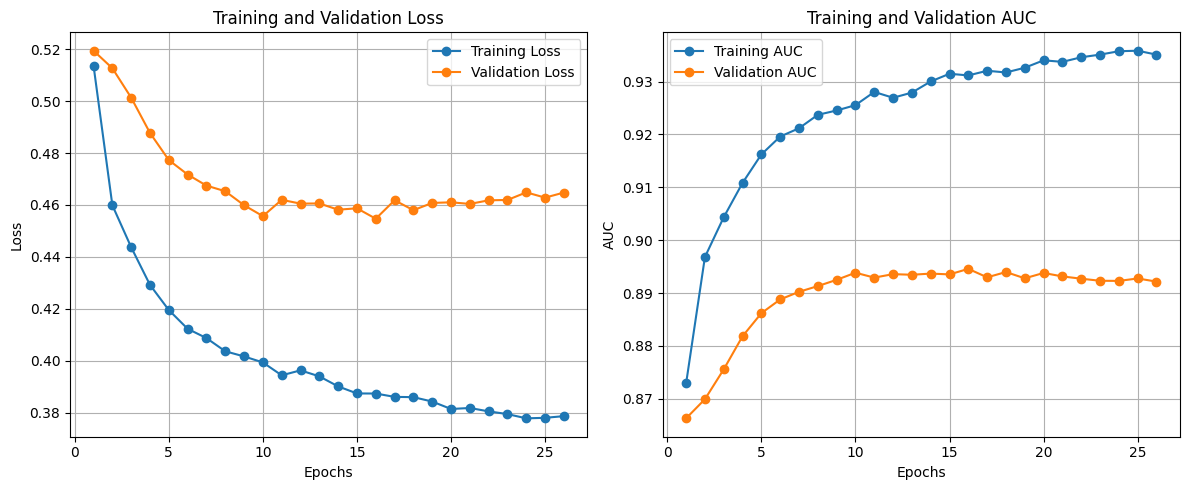

In [ ]:
# Extract metrics
loss = history.history['loss']
val_loss = history.history['val_loss']
auc = history.history['auc']
val_auc = history.history['val_auc']

epochs = range(1, len(loss)+1)

# Plot Loss
plt.figure(figsize=(12,5))

plt.subplot(1,2,1)
plt.plot(epochs, loss, label='Training Loss', marker='o')
plt.plot(epochs, val_loss, label='Validation Loss', marker='o')
plt.title('Training and Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

# Plot AUC
plt.subplot(1,2,2)
plt.plot(epochs, auc, label='Training AUC', marker='o')
plt.plot(epochs, val_auc, label='Validation AUC', marker='o')
plt.title('Training and Validation AUC')
plt.xlabel('Epochs')
plt.ylabel('AUC')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

In [ ]:
# Multi-Branch
# Inputs
meta_input = Input(shape=(X_meta_train.shape[1],), name="meta_input")

text_inputs = {}
text_reprs  = []

# Metadata branch
m = Dense(128, activation='swish', kernel_regularizer=l2(2e-5))(meta_input)
m = BatchNormalization()(m)
m = Dropout(0.4)(m)
meta_repr = Dense(64, activation='swish')(m)

# Fine-tuned text branches
for sec in sections:
    inp = Input(shape=(X_train_bert_ft_sec[sec].shape[1],), name=f"text_ft_{sec}")
    
    t = Dense(128, activation='swish', kernel_regularizer=l2(2e-5))(inp)
    t = BatchNormalization()(t)
    t = Dropout(0.3)(t)
    t = Dense(64, activation='swish')(t)
    
    text_inputs[sec] = inp
    text_reprs.append(t)

# Fusion
fusion = Concatenate()([meta_repr] + text_reprs)

z = Dense(256, activation='swish')(fusion)
z = BatchNormalization()(z)
z = Dropout(0.5)(z)

z = Dense(64, activation='swish')(z)
z = BatchNormalization()(z)

output = Dense(1, activation='sigmoid')(z)

model = Model(
    inputs=[meta_input] + [text_inputs[sec] for sec in sections],
    outputs=output
)

model.compile(
    optimizer=Adam(learning_rate=1e-4),
    loss=tf.keras.losses.BinaryCrossentropy(label_smoothing=0.02),
    metrics=["accuracy", tf.keras.metrics.AUC(name="auc")]
)

model.summary()

# callbacks
early_stop = EarlyStopping(
    monitor='val_auc',
    mode='max',
    patience=10,
    restore_best_weights=True,
    verbose=1
)

lr_scheduler = ReduceLROnPlateau(
    monitor='val_auc',
    mode='max',
    factor=0.5,
    patience=4,
    min_lr=1e-6,
    verbose=1
)

# Training
history = model.fit(
    [X_meta_train] + [X_train_bert_ft_sec[sec] for sec in sections],
    y_train_nn,
    validation_data=(
        [X_meta_val] + [X_val_bert_ft_sec[sec] for sec in sections],
        y_val_nn
    ),
    epochs=100,
    batch_size=64,
    callbacks=[early_stop, lr_scheduler],
    verbose=2
)

Model: "functional_31"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ meta_input          │ (None, 91)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ text_ft_name        │ (None, 256)       │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ text_ft_blurb       │ (None, 256)       │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ text_ft_story       │ (None, 256)       │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ text_ft_risks       │ (None, 256)       │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ text_ft_rewards     │ (None, 256)       │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_33 (Dense)    │ (None, 128)       │     11,776 │ meta_input[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_35 (Dense)    │ (None, 128)       │     32,896 │ text_ft_name[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_37 (Dense)    │ (None, 128)       │     32,896 │ text_ft_blurb[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_39 (Dense)    │ (None, 128)       │     32,896 │ text_ft_story[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_41 (Dense)    │ (None, 128)       │     32,896 │ text_ft_risks[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_43 (Dense)    │ (None, 128)       │     32,896 │ text_ft_rewards[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128)       │        512 │ dense_33[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128)       │        512 │ dense_35[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128)       │        512 │ dense_37[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128)       │        512 │ dense_39[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128)       │        512 │ dense_41[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128)       │        512 │ dense_43[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_20          │ (None, 128)       │          0 │ batch_normalizat

 Total params: 345,217 (1.32 MB)

 Trainable params: 343,041 (1.31 MB)

 Non-trainable params: 2,176 (8.50 KB)

Epoch 1/100
441/441 - 12s - 27ms/step - accuracy: 0.7860 - auc: 0.8661 - loss: 0.5042 - val_accuracy: 0.7969 - val_auc: 0.8852 - val_loss: 0.4737 - learning_rate: 1.0000e-04
Epoch 2/100
441/441 - 4s - 9ms/step - accuracy: 0.8106 - auc: 0.8902 - loss: 0.4550 - val_accuracy: 0.8043 - val_auc: 0.8911 - val_loss: 0.4620 - learning_rate: 1.0000e-04
Epoch 3/100
441/441 - 4s - 9ms/step - accuracy: 0.8194 - auc: 0.8993 - loss: 0.4361 - val_accuracy: 0.8098 - val_auc: 0.8946 - val_loss: 0.4522 - learning_rate: 1.0000e-04
Epoch 4/100
441/441 - 4s - 9ms/step - accuracy: 0.8244 - auc: 0.9052 - loss: 0.4237 - val_accuracy: 0.8114 - val_auc: 0.8961 - val_loss: 0.4479 - learning_rate: 1.0000e-04
Epoch 5/100
441/441 - 4s - 9ms/step - accuracy: 0.8286 - auc: 0.9084 - loss: 0.4180 - val_accuracy: 0.8127 - val_auc: 0.8978 - val_loss: 0.4449 - learning_rate: 1.0000e-04
Epoch 6/100
441/441 - 4s - 9ms/step - accuracy: 0.8320 - auc: 0.9117 - loss: 0.4106 - val_accuracy: 0.8151 - val_auc: 0.9001 - val_loss: 0

In [ ]:
# Final Evaluation
# Prepare the multi-input list for evaluation
X_test_multi = [X_meta_test] + [X_test_bert_ft_sec[sec] for sec in sections]

# Get raw predictions and metrics
results = model.evaluate(X_test_multi, y_test_nn, verbose=0)
y_pred_prob = model.predict(X_test_multi, verbose=0)
y_pred = (y_pred_prob > 0.5).astype(int)

# Calculate specific metrics
precision = precision_score(y_test_nn, y_pred)
recall = recall_score(y_test_nn, y_pred)
f1 = f1_score(y_test_nn, y_pred)

print(f"Multi-Branch Sectional Results")
print(f"Test Loss:     {results[0]:.4f}")
print(f"Test Accuracy: {results[1]:.4f}")
print(f"Test AUC:      {results[2]:.4f}")
print(f"Test Precision:{precision:.4f}")
print(f"Test Recall:   {recall:.4f}")
print(f"Test F1-score: {f1:.4f}")

print("\nFull Classification Report:")
print(classification_report(y_test_nn, y_pred))

--- Multi-Branch Sectional Results ---
Test Loss:     0.4371
Test Accuracy: 0.8113
Test AUC:      0.8993
Test Precision:0.7875
Test Recall:   0.8628
Test F1-score: 0.8235

Full Classification Report:
              precision    recall  f1-score   support

           0       0.84      0.76      0.80      2962
           1       0.79      0.86      0.82      3084

    accuracy                           0.81      6046
   macro avg       0.81      0.81      0.81      6046
weighted avg       0.81      0.81      0.81      6046



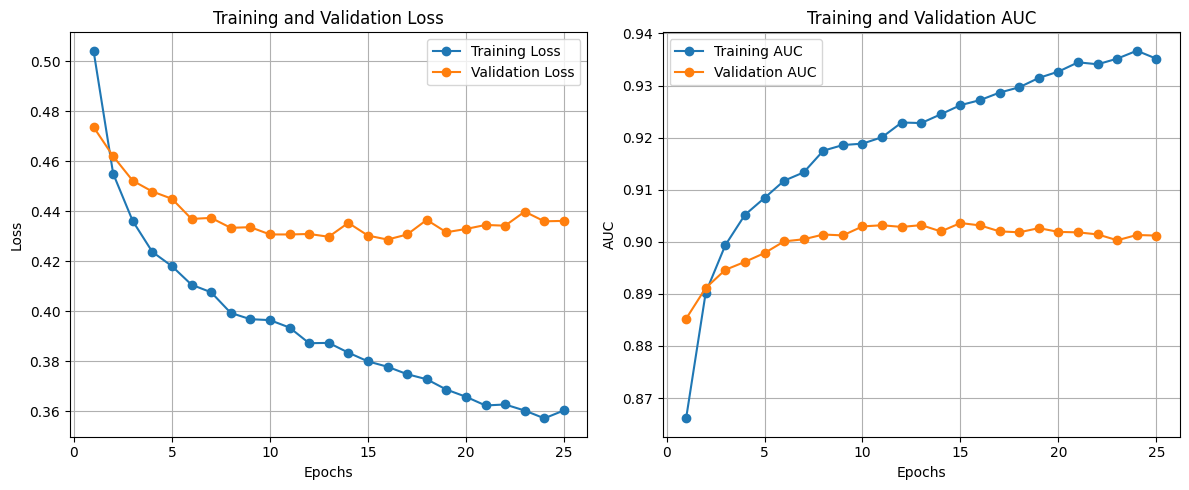

In [ ]:
# Extract metrics 
loss = history.history['loss']
val_loss = history.history['val_loss']
auc = history.history['auc']
val_auc = history.history['val_auc']

epochs = range(1, len(loss)+1)

# Plot Loss
plt.figure(figsize=(12,5))

plt.subplot(1,2,1)
plt.plot(epochs, loss, label='Training Loss', marker='o')
plt.plot(epochs, val_loss, label='Validation Loss', marker='o')
plt.title('Training and Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

# Plot AUC
plt.subplot(1,2,2)
plt.plot(epochs, auc, label='Training AUC', marker='o')
plt.plot(epochs, val_auc, label='Validation AUC', marker='o')
plt.title('Training and Validation AUC')
plt.xlabel('Epochs')
plt.ylabel('AUC')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

In [ ]:
# Inputs
meta_input = Input(shape=(X_meta_train.shape[1],), name="meta_input")

text_inputs = {}
text_reprs = []

# Metadata Branch (Encoder)
m = Dense(128, activation='swish', kernel_regularizer=l2(2e-5))(meta_input)
m = BatchNormalization()(m)
m = Dropout(0.4)(m)
meta_repr = Dense(64, activation='swish', name="meta_feature_extractor")(m)

# Sectional Text Branches
for sec in sections:
    inp = Input(shape=(X_train_bert_ft_sec[sec].shape[1],), name=f"text_ft_{sec}")
    
    t = Dense(128, activation='swish', kernel_regularizer=l2(2e-5))(inp)
    t = BatchNormalization()(t)
    t = Dropout(0.3)(t)
    t = Dense(64, activation='swish', name=f"repr_{sec}")(t)
    
    text_inputs[sec] = inp
    text_reprs.append(t)

# Fusion with Residual Bypass
# Initial Fusion: Concatenate metadata features with all text section features
fusion_all = Concatenate()([meta_repr] + text_reprs)

# Deep Interaction Layer
z = Dense(256, activation='swish')(fusion_all)
z = BatchNormalization()(z)
z = Dropout(0.5)(z)

# Residual bypass
# Re-inject the original metadata representation directly into the late-stage logic
z = Concatenate(name="residual_bypass_layer")([z, meta_repr])

# Final Feature Refinement
z = Dense(64, activation='swish')(z)
z = BatchNormalization()(z)

# Output Layer
output = Dense(1, activation='sigmoid', name="final_decision")(z)

# Model Definition & Compilation
model = Model(
    inputs=[meta_input] + [text_inputs[sec] for sec in sections],
    outputs=output
)

model.compile(
    optimizer=Adam(learning_rate=1e-4),
    loss=tf.keras.losses.BinaryCrossentropy(label_smoothing=0.05),
    metrics=["accuracy", tf.keras.metrics.AUC(name="auc")]
)

model.summary()

# Callbacks & Training
early_stop = EarlyStopping(
    monitor='val_auc', 
    mode='max', 
    patience=10, 
    restore_best_weights=True, 
    verbose=1
)

lr_scheduler = ReduceLROnPlateau(
    monitor='val_auc', 
    mode='max', 
    factor=0.5, 
    patience=5, 
    min_lr=1e-6, 
    verbose=1
)

history = model.fit(
    [X_meta_train] + [X_train_bert_ft_sec[sec] for sec in sections],
    y_train_nn,
    validation_data=(
        [X_meta_val] + [X_val_bert_ft_sec[sec] for sec in sections],
        y_val_nn
    ),
    epochs=100,
    batch_size=32, 
    callbacks=[early_stop, lr_scheduler],
    verbose=2
)

# Evaluation
results = model.evaluate(
    [X_meta_test] + [X_test_bert_ft_sec[sec] for sec in sections],
    y_test_nn,
    verbose=0
)

print(f"\nTest Accuracy: {results[1]:.4f}")
print(f"Test AUC: {results[2]:.4f}")

Model: "functional_33"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ meta_input          │ (None, 91)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ text_ft_name        │ (None, 256)       │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ text_ft_blurb       │ (None, 256)       │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ text_ft_story       │ (None, 256)       │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ text_ft_risks       │ (None, 256)       │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ text_ft_rewards     │ (None, 256)       │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_56 (Dense)    │ (None, 128)       │     11,776 │ meta_input[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_57 (Dense)    │ (None, 128)       │     32,896 │ text_ft_name[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_58 (Dense)    │ (None, 128)       │     32,896 │ text_ft_blurb[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_59 (Dense)    │ (None, 128)       │     32,896 │ text_ft_story[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_60 (Dense)    │ (None, 128)       │     32,896 │ text_ft_risks[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_61 (Dense)    │ (None, 128)       │     32,896 │ text_ft_rewards[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128)       │        512 │ dense_56[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128)       │        512 │ dense_57[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128)       │        512 │ dense_58[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128)       │        512 │ dense_59[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128)       │        512 │ dense_60[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128)       │        512 │ dense_61[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_34          │ (None, 128)       │          0 │ batch_normalizat

 Total params: 349,313 (1.33 MB)

 Trainable params: 347,137 (1.32 MB)

 Non-trainable params: 2,176 (8.50 KB)

Epoch 1/100
882/882 - 15s - 17ms/step - accuracy: 0.7936 - auc: 0.8735 - loss: 0.5039 - val_accuracy: 0.7992 - val_auc: 0.8855 - val_loss: 0.4855 - learning_rate: 1.0000e-04
Epoch 2/100
882/882 - 7s - 8ms/step - accuracy: 0.8157 - auc: 0.8947 - loss: 0.4657 - val_accuracy: 0.8099 - val_auc: 0.8926 - val_loss: 0.4689 - learning_rate: 1.0000e-04
Epoch 3/100
882/882 - 7s - 8ms/step - accuracy: 0.8241 - auc: 0.9021 - loss: 0.4521 - val_accuracy: 0.8106 - val_auc: 0.8940 - val_loss: 0.4653 - learning_rate: 1.0000e-04
Epoch 4/100
882/882 - 7s - 8ms/step - accuracy: 0.8250 - auc: 0.9048 - loss: 0.4465 - val_accuracy: 0.8139 - val_auc: 0.8962 - val_loss: 0.4593 - learning_rate: 1.0000e-04
Epoch 5/100
882/882 - 7s - 8ms/step - accuracy: 0.8303 - auc: 0.9089 - loss: 0.4390 - val_accuracy: 0.8136 - val_auc: 0.8964 - val_loss: 0.4600 - learning_rate: 1.0000e-04
Epoch 6/100
882/882 - 7s - 8ms/step - accuracy: 0.8313 - auc: 0.9113 - loss: 0.4343 - val_accuracy: 0.8162 - val_auc: 0.8978 - val_loss: 0

In [ ]:
# Prepare test inputs for multi-input model
test_inputs = [X_meta_test] + [X_test_bert_ft_sec[sec] for sec in sections]

# Predict probabilities
y_pred_prob = model.predict(test_inputs, verbose=0).ravel()

# Convert probabilities to binary class (Threshold 0.5)
y_pred = (y_pred_prob >= 0.5).astype(int)

# Ensure y_true is a 1D array to match y_pred
y_true = np.array(y_test_nn).ravel()

# Metrics
precision = precision_score(y_true, y_pred)
recall    = recall_score(y_true, y_pred)
f1        = f1_score(y_true, y_pred)
auc_score = roc_auc_score(y_true, y_pred_prob)

print("Test Metrics (Residual Multi-Branch)")
print(f"AUC:        {auc_score:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-score:  {f1:.4f}")

# Classification Report
print("\nClassification Report:")
print(classification_report(y_true, y_pred, target_names=['Failure (0)', 'Success (1)']))

# Confusion Matrix
cm = confusion_matrix(y_true, y_pred)
print("\nConfusion Matrix:")
print(cm)

tn, fp, fn, tp = cm.ravel()
print(f"True Negatives:  {tn} | False Positives: {fp}")
print(f"False Negatives: {fn} | True Positives:  {tp}")


===== Test Metrics (Residual Multi-Branch) =====
AUC:        0.9002
Precision: 0.8104
Recall:    0.8304
F1-score:  0.8203

Classification Report:
              precision    recall  f1-score   support

 Failure (0)       0.82      0.80      0.81      2962
 Success (1)       0.81      0.83      0.82      3084

    accuracy                           0.81      6046
   macro avg       0.81      0.81      0.81      6046
weighted avg       0.81      0.81      0.81      6046


Confusion Matrix:
[[2363  599]
 [ 523 2561]]

Breakdown:
True Negatives:  2363 | False Positives: 599
False Negatives: 523 | True Positives:  2561


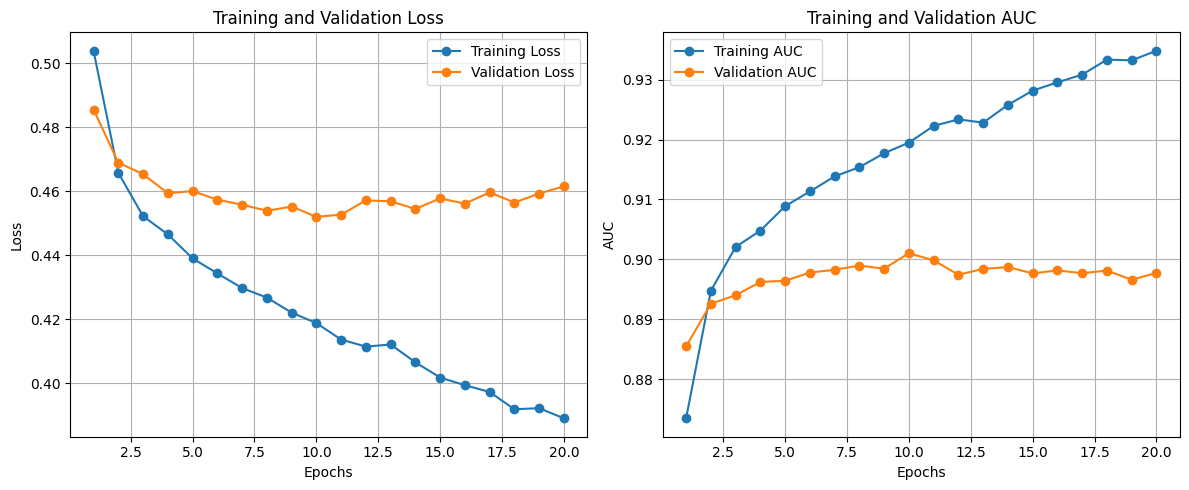

In [ ]:
# Extract metrics
loss = history.history['loss']
val_loss = history.history['val_loss']
auc = history.history['auc']
val_auc = history.history['val_auc']

epochs = range(1, len(loss)+1)

# Plot Loss
plt.figure(figsize=(12,5))

plt.subplot(1,2,1)
plt.plot(epochs, loss, label='Training Loss', marker='o')
plt.plot(epochs, val_loss, label='Validation Loss', marker='o')
plt.title('Training and Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

# Plot AUC
plt.subplot(1,2,2)
plt.plot(epochs, auc, label='Training AUC', marker='o')
plt.plot(epochs, val_auc, label='Validation AUC', marker='o')
plt.title('Training and Validation AUC')
plt.xlabel('Epochs')
plt.ylabel('AUC')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

Text only model

In [ ]:
# Data (Text Only)
X_train = X_train_bert_ft
X_val   = X_val_bert_ft
X_test  = X_test_bert_ft

y_train_nn = y_train_meta
y_val_nn   = y_val_meta
y_test_nn  = y_test_meta

input_dim = X_train.shape[1]

# Model Architecture
inputs = Input(shape=(input_dim,))

x = Dense(256, activation="relu", kernel_regularizer=l2(1e-5))(inputs)
x = BatchNormalization()(x)
x = Dropout(0.5)(x)

x = Dense(64, activation="relu", kernel_regularizer=l2(1e-5))(x)
x = BatchNormalization()(x)
x = Dropout(0.4)(x)

outputs = Dense(1, activation="sigmoid")(x)

model = Model(inputs=inputs, outputs=outputs)

# Compile Model
model.compile(
    optimizer=Adam(learning_rate=1e-4),
    loss=tf.keras.losses.BinaryCrossentropy(label_smoothing=0.05),
    metrics=["accuracy", tf.keras.metrics.AUC(name="auc")]
)

# Callbacks
early_stop = EarlyStopping(
    monitor="val_auc",
    mode="max",
    patience=15,
    restore_best_weights=True,
    verbose=1
)

lr_scheduler = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=5,
    min_lr=1e-6,
    verbose=1
)

# Training
history = model.fit(
    X_train,
    y_train_nn,
    validation_data=(X_val, y_val_nn),
    epochs=100,
    batch_size=64,
    callbacks=[early_stop, lr_scheduler],
    verbose=2
)

# Evaluation
results = model.evaluate(X_test, y_test_nn, verbose=0)

print(f"\nTest Loss: {results[0]:.4f}")
print(f"Test Accuracy: {results[1]:.4f}")
print(f"Test AUC: {results[2]:.4f}")

Epoch 1/100


E0000 00:00:1774270218.795713    1788 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


441/441 - 5s - 11ms/step - accuracy: 0.7887 - auc: 0.8649 - loss: 0.5337 - val_accuracy: 0.7679 - val_auc: 0.8608 - val_loss: 0.5306 - learning_rate: 1.0000e-04
Epoch 2/100
441/441 - 3s - 6ms/step - accuracy: 0.8149 - auc: 0.8883 - loss: 0.4819 - val_accuracy: 0.7745 - val_auc: 0.8610 - val_loss: 0.5430 - learning_rate: 1.0000e-04
Epoch 3/100
441/441 - 3s - 6ms/step - accuracy: 0.8186 - auc: 0.8908 - loss: 0.4700 - val_accuracy: 0.7737 - val_auc: 0.8612 - val_loss: 0.5311 - learning_rate: 1.0000e-04
Epoch 4/100
441/441 - 3s - 6ms/step - accuracy: 0.8205 - auc: 0.8960 - loss: 0.4573 - val_accuracy: 0.7752 - val_auc: 0.8615 - val_loss: 0.5227 - learning_rate: 1.0000e-04
Epoch 5/100
441/441 - 2s - 6ms/step - accuracy: 0.8256 - auc: 0.8984 - loss: 0.4518 - val_accuracy: 0.7782 - val_auc: 0.8620 - val_loss: 0.5174 - learning_rate: 1.0000e-04
Epoch 6/100
441/441 - 2s - 6ms/step - accuracy: 0.8276 - auc: 0.9004 - loss: 0.4472 - val_accuracy: 0.7782 - val_auc: 0.8621 - val_loss: 0.5135 - learn

In [ ]:
# Predictions
y_pred_prob = model.predict(X_test)
y_pred = (y_pred_prob >= 0.5).astype(int)

# Flatten
y_pred = y_pred.ravel()
y_true = y_test_nn.ravel()

# Metrics
precision = precision_score(y_true, y_pred)
recall    = recall_score(y_true, y_pred)
f1        = f1_score(y_true, y_pred)

print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-score:  {f1:.4f}")

print("\nClassification Report:")
print(classification_report(y_true, y_pred))

189/189 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
Precision: 0.7668
Recall:    0.8009
F1-score:  0.7835

Classification Report:
              precision    recall  f1-score   support

           0       0.78      0.75      0.76      2962
           1       0.77      0.80      0.78      3084

    accuracy                           0.77      6046
   macro avg       0.77      0.77      0.77      6046
weighted avg       0.77      0.77      0.77      6046



Meta + Text + Images

In [ ]:
def train_xgboost3(X_train, X_val, X_test,
                   y_train, y_val, y_test,
                   feature_names,
                   model_name="XGBoost (RandomizedSearch)"):

    print(f"\nTraining {model_name} ...")
    start_time = time.time()

    # Base model
    base_model = xgb.XGBClassifier(
        objective='binary:logistic',
        eval_metric='auc',
        subsample=0.8,
        colsample_bytree=0.8,
        random_state=42,
        n_jobs=-1
    )

    # Search Space
    param_grid = {
        'n_estimators': [300, 500],
        'max_depth': [4, 6],
        'learning_rate': [0.01, 0.05],
        'gamma': [0, 0.1],
        'min_child_weight': [1, 3, 5]
    }

    cv = StratifiedKFold(
        n_splits=5,
        shuffle=True,
        random_state=42
    )

    # Randomized Search
    grid_search = RandomizedSearchCV(
        estimator=base_model,
        param_distributions=param_grid,
        n_iter=10,
        scoring='roc_auc',
        cv=cv,
        verbose=3,
        n_jobs=-1,
        random_state=42
    )

    print("\nRunning hyperparameter search...")

    grid_search.fit(X_train, y_train)

    print("\nBest parameters found:")
    print(grid_search.best_params_)

    search_time = time.time()
    print(f"Search time: {search_time - start_time:.2f} seconds")

    # Final Model Training (Early Stopping)
    print("\nTraining final model with early stopping...")

    best_model = grid_search.best_estimator_

    best_model.set_params(
        early_stopping_rounds=50,
        n_estimators=grid_search.best_params_['n_estimators']
    )

    best_model.fit(
        X_train,
        y_train,
        eval_set=[(X_val, y_val)],
        verbose=True
    )

    # Evaluation
    y_pred = best_model.predict(X_test)
    y_pred_proba = best_model.predict_proba(X_test)[:, 1]

    print("XGBoost Final Evaluation")
    print("Test ROC-AUC:", roc_auc_score(y_test, y_pred_proba))
    print("Test Accuracy:", accuracy_score(y_test, y_pred))
    print("\nClassification Report:\n")
    print(classification_report(y_test, y_pred))

    end_time = time.time()
    print(f"\nTotal training time: {end_time - start_time:.2f} seconds")

    return best_model

In [ ]:
xgb_model_multimodal = train_xgboost3(
    X_train_multimodal,
    X_val_multimodal,
    X_test_multimodal,
    y_train_meta,
    y_val_meta,
    y_test_meta,
    feature_names=None
)

In [ ]:
# Tri-Modal Residual Multi-Branch (Sectional Text)

# Data
X_meta_train = X_train_meta_dense
X_meta_val   = X_val_meta_dense
X_meta_test  = X_test_meta_dense

X_img_train = X_train_img
X_img_val   = X_val_img
X_img_test  = X_test_img

y_train_nn = y_train_meta
y_val_nn   = y_val_meta
y_test_nn  = y_test_meta

# Inputs
meta_input = Input(shape=(X_meta_train.shape[1],), name="meta_input")
img_input  = Input(shape=(X_img_train.shape[1],), name="img_input")

text_inputs = {}
text_reprs  = []

# Metadata Branch
m = Dense(128, activation='swish', kernel_regularizer=l2(2e-5))(meta_input)
m = BatchNormalization()(m)
m = Dropout(0.4)(m)
meta_repr = Dense(64, activation='swish', name="meta_feature_extractor")(m)

# Image Branch (ResNet embeddings)
i = Dense(128, activation='swish', kernel_regularizer=l2(2e-5))(img_input)
i = BatchNormalization()(i)
i = Dropout(0.3)(i)
img_repr = Dense(64, activation='swish', name="img_feature_extractor")(i)

# Text Section Branches
for sec in sections:
    inp = Input(shape=(X_train_bert_ft_sec[sec].shape[1],), name=f"text_ft_{sec}")
    
    t = Dense(128, activation='swish', kernel_regularizer=l2(2e-5))(inp)
    t = BatchNormalization()(t)
    t = Dropout(0.3)(t)
    t = Dense(64, activation='swish', name=f"repr_{sec}")(t)
    
    text_inputs[sec] = inp
    text_reprs.append(t)

# Fusion
fusion_all = Concatenate()([meta_repr, img_repr] + text_reprs)

# Deep Interaction
z = Dense(256, activation='swish')(fusion_all)
z = BatchNormalization()(z)
z = Dropout(0.5)(z)

# Residual Bypass (meta)
z = Concatenate(name="residual_bypass")([z, meta_repr])

# Final Layers
z = Dense(64, activation='swish')(z)
z = BatchNormalization()(z)

output = Dense(1, activation='sigmoid', name="final_decision")(z)

# Model
model = Model(
    inputs=[meta_input, img_input] + [text_inputs[sec] for sec in sections],
    outputs=output
)

model.compile(
    optimizer=Adam(learning_rate=1e-4),
    loss=tf.keras.losses.BinaryCrossentropy(label_smoothing=0.05),
    metrics=["accuracy", tf.keras.metrics.AUC(name="auc")]
)

model.summary()

# Callbacks
early_stop = EarlyStopping(
    monitor='val_auc',
    mode='max',
    patience=10,
    restore_best_weights=True,
    verbose=1
)

lr_scheduler = ReduceLROnPlateau(
    monitor='val_auc',
    mode='max',
    factor=0.5,
    patience=5,
    min_lr=1e-6,
    verbose=1
)

# Training
history = model.fit(
    [X_meta_train, X_img_train] + [X_train_bert_ft_sec[sec] for sec in sections],
    y_train_nn,
    validation_data=(
        [X_meta_val, X_img_val] + [X_val_bert_ft_sec[sec] for sec in sections],
        y_val_nn
    ),
    epochs=100,
    batch_size=32,
    callbacks=[early_stop, lr_scheduler],
    verbose=2
)

# Evaluation
test_inputs = [X_meta_test, X_img_test] + [X_test_bert_ft_sec[sec] for sec in sections]

results = model.evaluate(test_inputs, y_test_nn, verbose=0)

print(f"\nTest Loss:     {results[0]:.4f}")
print(f"Test Accuracy: {results[1]:.4f}")
print(f"Test AUC:      {results[2]:.4f}")

# Predictions + Metrics
y_pred_prob = model.predict(test_inputs, verbose=0).ravel()
y_pred = (y_pred_prob >= 0.5).astype(int)
y_true = np.array(y_test_nn).ravel()

precision = precision_score(y_true, y_pred)
recall    = recall_score(y_true, y_pred)
f1        = f1_score(y_true, y_pred)
auc_score = roc_auc_score(y_true, y_pred_prob)

print("TRI-MODAL RESULTS")
print(f"AUC:        {auc_score:.4f}")
print(f"Precision:  {precision:.4f}")
print(f"Recall:     {recall:.4f}")
print(f"F1-score:   {f1:.4f}")

print("\nClassification Report:")
print(classification_report(y_true, y_pred, target_names=['Failure (0)', 'Success (1)']))

cm = confusion_matrix(y_true, y_pred)
print("\nConfusion Matrix:")
print(cm)

tn, fp, fn, tp = cm.ravel()
print(f"\nTN: {tn} | FP: {fp}")
print(f"FN: {fn} | TP: {tp}")

Model: "functional_22"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ meta_input          │ (None, 91)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ img_input           │ (None, 2048)      │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ text_ft_name        │ (None, 256)       │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ text_ft_blurb       │ (None, 256)       │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ text_ft_story       │ (None, 256)       │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ text_ft_risks       │ (None, 256)       │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ text_ft_rewards     │ (None, 256)       │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_307 (Dense)   │ (None, 128)       │     11,776 │ meta_input[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_308 (Dense)   │ (None, 128)       │    262,272 │ img_input[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_309 (Dense)   │ (None, 128)       │     32,896 │ text_ft_name[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_310 (Dense)   │ (None, 128)       │     32,896 │ text_ft_blurb[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_311 (Dense)   │ (None, 128)       │     32,896 │ text_ft_story[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_312 (Dense)   │ (None, 128)       │     32,896 │ text_ft_risks[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_313 (Dense)   │ (None, 128)       │     32,896 │ text_ft_rewards[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128)       │        512 │ dense_307[0][0]   │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128)       │        512 │ dense_308[0][0]   │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128)       │        512 │ dense_309[0][0]   │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128)       │        512 │ dense_310[0][0]   │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128)       │        512 │ dense_311[0][0]   │
│ (BatchNormalizatio… │                   │            │                 

 Total params: 636,737 (2.43 MB)

 Trainable params: 634,305 (2.42 MB)

 Non-trainable params: 2,432 (9.50 KB)

Epoch 1/100
882/882 - 18s - 20ms/step - accuracy: 0.7907 - auc: 0.8707 - loss: 0.5168 - val_accuracy: 0.8020 - val_auc: 0.8881 - val_loss: 0.4838 - learning_rate: 1.0000e-04
Epoch 2/100
882/882 - 10s - 11ms/step - accuracy: 0.8157 - auc: 0.8952 - loss: 0.4709 - val_accuracy: 0.8089 - val_auc: 0.8924 - val_loss: 0.4759 - learning_rate: 1.0000e-04
Epoch 3/100
882/882 - 10s - 11ms/step - accuracy: 0.8226 - auc: 0.9021 - loss: 0.4577 - val_accuracy: 0.8104 - val_auc: 0.8958 - val_loss: 0.4680 - learning_rate: 1.0000e-04
Epoch 4/100
882/882 - 10s - 11ms/step - accuracy: 0.8302 - auc: 0.9090 - loss: 0.4450 - val_accuracy: 0.8127 - val_auc: 0.8973 - val_loss: 0.4645 - learning_rate: 1.0000e-04
Epoch 5/100
882/882 - 10s - 11ms/step - accuracy: 0.8342 - auc: 0.9132 - loss: 0.4371 - val_accuracy: 0.8159 - val_auc: 0.8991 - val_loss: 0.4621 - learning_rate: 1.0000e-04
Epoch 6/100
882/882 - 10s - 11ms/step - accuracy: 0.8393 - auc: 0.9163 - loss: 0.4310 - val_accuracy: 0.8197 - val_auc: 0.8986 - v

In [ ]:
# Tri-Modal Gated Fusion
sections = ["name", "blurb", "story", "risks", "rewards"]

# Inputs
meta_input = Input(shape=(X_train_meta_dense.shape[1],), name="meta_input")
img_input  = Input(shape=(X_train_img.shape[1],), name="img_input")

text_inputs = {}
text_reprs = []

# Text Branch (SECTIONAL)
for sec in sections:
    inp = Input(shape=(X_train_bert_ft_sec[sec].shape[1],), name=f"text_{sec}")
    
    t = Dense(256, activation="relu", kernel_regularizer=l2(1e-4))(inp)
    t = BatchNormalization()(t)
    t = Dropout(0.4)(t)
    t = Dense(64, activation="relu", kernel_regularizer=l2(1e-4))(t)
    
    text_inputs[sec] = inp
    text_reprs.append(t)

# Concatenate all section representations
text_combined = Concatenate()(text_reprs)

# compression (128 dim)
text_repr = Dense(128, activation="relu")(text_combined)

# Metadata Branch
m = Dense(128, activation="relu", kernel_regularizer=l2(1e-4))(meta_input)
m = BatchNormalization()(m)
m = Dropout(0.4)(m)
m = Dense(64, activation="relu")(m)

# Gating for meta
m_gate = Dense(64, activation="sigmoid")(m)
m = Multiply()([m, m_gate])

# Image Branch
i = Dense(256, activation="relu", kernel_regularizer=l2(1e-4))(img_input)
i = BatchNormalization()(i)
i = Dropout(0.5)(i)
i = Dense(64, activation="relu")(i)

# Gating for image
i_gate = Dense(64, activation="sigmoid")(i)
i = Multiply()([i, i_gate])

# Text Gating
t_gate = Dense(128, activation="sigmoid")(text_repr)
t = Multiply()([text_repr, t_gate])

# Fusion Layer
combined = Concatenate()([m, t, i])

# Head
x = Dense(256, activation="relu", kernel_regularizer=l2(1e-4))(combined)
x = BatchNormalization()(x)
x = Dropout(0.5)(x)

x = Dense(128, activation="relu", kernel_regularizer=l2(1e-4))(x)
x = Dropout(0.4)(x)

output = Dense(1, activation="sigmoid")(x)

# Model
multimodal_model_sectional = Model(
    inputs=[meta_input, img_input] + [text_inputs[sec] for sec in sections],
    outputs=output
)

# Compile
multimodal_model_sectional.compile(
    optimizer=Adam(learning_rate=3e-4),
    loss=tf.keras.losses.BinaryCrossentropy(label_smoothing=0.1),
    metrics=["accuracy", tf.keras.metrics.AUC(name="auc")]
)

multimodal_model_sectional.summary()

# Callbacks
early_stop = EarlyStopping(
    monitor="val_auc",
    mode="max",
    patience=15,
    restore_best_weights=True,
    verbose=1
)

reduce_lr = ReduceLROnPlateau(
    monitor="val_auc",
    mode="max",
    factor=0.5,
    patience=5,
    min_lr=1e-6,
    verbose=1
)

# Train
history = multimodal_model_sectional.fit(
    [X_train_meta_dense, X_train_img] + [X_train_bert_ft_sec[sec] for sec in sections],
    y_train_meta,
    validation_data=(
        [X_val_meta_dense, X_val_img] + [X_val_bert_ft_sec[sec] for sec in sections],
        y_val_meta
    ),
    epochs=100,
    batch_size=64,
    callbacks=[early_stop, reduce_lr],
    verbose=2
)

results = multimodal_model_sectional.evaluate(
    [X_test_meta_dense, X_test_img] + [X_test_bert_ft_sec[sec] for sec in sections],
    y_test_meta,
    verbose=0
)

# Metrics
print(f"\nTest Accuracy: {results[1]:.4f}")
print(f"Test AUC:      {results[2]:.4f}")
y_pred_prob = multimodal_model_sectional.predict(
    [X_test_meta_dense, X_test_img] + [X_test_bert_ft_sec[sec] for sec in sections],
    verbose=0
).ravel()
y_pred = (y_pred_prob >= 0.5).astype(int)
y_true = np.array(y_test_meta).ravel()
precision = precision_score(y_true, y_pred)
recall    = recall_score(y_true, y_pred)
f1        = f1_score(y_true, y_pred)
auc_score = roc_auc_score(y_true, y_pred_prob)
print("\n TRI-MODAL SECTIONAL + GATING RESULTS ")
print(f"AUC:        {auc_score:.4f}")
print(f"Precision:  {precision:.4f}")
print(f"Recall:     {recall:.4f}")
print(f"F1-score:   {f1:.4f}")

Model: "functional_6"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ text_name           │ (None, 256)       │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ text_blurb          │ (None, 256)       │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ text_story          │ (None, 256)       │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ text_risks          │ (None, 256)       │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ text_rewards        │ (None, 256)       │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_114 (Dense)   │ (None, 256)       │     65,792 │ text_name[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_116 (Dense)   │ (None, 256)       │     65,792 │ text_blurb[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_118 (Dense)   │ (None, 256)       │     65,792 │ text_story[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_120 (Dense)   │ (None, 256)       │     65,792 │ text_risks[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_122 (Dense)   │ (None, 256)       │     65,792 │ text_rewards[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ meta_input          │ (None, 91)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 256)       │      1,024 │ dense_114[0][0]   │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 256)       │      1,024 │ dense_116[0][0]   │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 256)       │      1,024 │ dense_118[0][0]   │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 256)       │      1,024 │ dense_120[0][0]   │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 256)       │      1,024 │ dense_122[0][0]   │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ img_input           │ (None, 2048)      │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_125 (Dense)   │ (None, 128)       │     11,776 │ meta_input[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_51          │ (None, 256)       │          0 │ batch_normalizat

 Total params: 1,144,641 (4.37 MB)

 Trainable params: 1,140,801 (4.35 MB)

 Non-trainable params: 3,840 (15.00 KB)

Epoch 1/100
441/441 - 16s - 36ms/step - accuracy: 0.7586 - auc: 0.8326 - loss: 0.8676 - val_accuracy: 0.7914 - val_auc: 0.8729 - val_loss: 0.7687 - learning_rate: 3.0000e-04
Epoch 2/100
441/441 - 5s - 11ms/step - accuracy: 0.7999 - auc: 0.8774 - loss: 0.7615 - val_accuracy: 0.8020 - val_auc: 0.8851 - val_loss: 0.7354 - learning_rate: 3.0000e-04
Epoch 3/100
441/441 - 5s - 11ms/step - accuracy: 0.8147 - auc: 0.8931 - loss: 0.7229 - val_accuracy: 0.8094 - val_auc: 0.8931 - val_loss: 0.7096 - learning_rate: 3.0000e-04
Epoch 4/100
441/441 - 5s - 11ms/step - accuracy: 0.8279 - auc: 0.9038 - loss: 0.6929 - val_accuracy: 0.8167 - val_auc: 0.8975 - val_loss: 0.6916 - learning_rate: 3.0000e-04
Epoch 5/100
441/441 - 5s - 11ms/step - accuracy: 0.8342 - auc: 0.9108 - loss: 0.6694 - val_accuracy: 0.8190 - val_auc: 0.8993 - val_loss: 0.6779 - learning_rate: 3.0000e-04
Epoch 6/100
441/441 - 5s - 11ms/step - accuracy: 0.8400 - auc: 0.9156 - loss: 0.6485 - val_accuracy: 0.8225 - val_auc: 0.9017 - val_lo

In [ ]:
# Feature-Level Gated Fusion
sections = ["name", "blurb", "story", "risks", "rewards"]

# Inputs
meta_input = Input(shape=(X_train_meta_dense.shape[1],), name="meta_input")
img_input  = Input(shape=(X_train_img.shape[1],), name="img_input")

text_inputs = {}
text_reprs = []

# Text Branch (SECTIONAL)
for sec in sections:
    inp = Input(shape=(X_train_bert_ft_sec[sec].shape[1],), name=f"text_{sec}")
    
    t = Dense(256, activation='swish', kernel_regularizer=l2(1e-5))(inp)
    t = BatchNormalization()(t)
    t = Dropout(0.4)(t)
    t = Dense(64, activation='swish')(t)
    
    text_inputs[sec] = inp
    text_reprs.append(t)

text_combined = Concatenate()(text_reprs)

# Compress to stable size
text_repr = Dense(128, activation='swish')(text_combined)

# Metadata Branch
m = Dense(128, activation='swish', kernel_regularizer=l2(1e-5))(meta_input)
m = BatchNormalization()(m)
m = Dropout(0.4)(m)
meta_repr = Dense(64, activation='swish')(m)

# Image Branch
i = Dense(256, activation='swish', kernel_regularizer=l2(1e-5))(img_input)
i = BatchNormalization()(i)
i = Dropout(0.4)(i)
img_repr = Dense(128, activation='swish')(i)

# Feature-Level Gating
# Gates now match feature dimensions
gate_meta = Dense(64, activation='sigmoid')(meta_repr)
gate_text = Dense(128, activation='sigmoid')(text_repr)
gate_img  = Dense(128, activation='sigmoid')(img_repr)

# Apply gates element-wise
weighted_meta = Multiply()([meta_repr, gate_meta])
weighted_text = Multiply()([text_repr, gate_text])
weighted_img  = Multiply()([img_repr, gate_img])

# Fusion after gating
fusion = Concatenate()([
    weighted_meta,
    weighted_text,
    weighted_img
])

# Head
z = Dense(256, activation='swish')(fusion)
z = BatchNormalization()(z)
z = Dropout(0.5)(z)

z = Dense(64, activation='swish')(z)
z = BatchNormalization()(z)

output = Dense(1, activation='sigmoid')(z)

# Model
model = Model(
    inputs=[meta_input, img_input] + [text_inputs[sec] for sec in sections],
    outputs=output
)

model.compile(
    optimizer=Adam(learning_rate=8e-5),
    loss=tf.keras.losses.BinaryCrossentropy(label_smoothing=0.02),
    metrics=["accuracy", tf.keras.metrics.AUC(name="auc")]
)

model.summary()

# callbacks
early_stop = EarlyStopping(
    monitor='val_auc', mode='max', patience=15, restore_best_weights=True, verbose=1
)

lr_scheduler = ReduceLROnPlateau(
    monitor='val_auc', mode='max', factor=0.5, patience=5, min_lr=1e-6, verbose=1
)

history = model.fit(
    [X_train_meta_dense, X_train_img] + [X_train_bert_ft_sec[sec] for sec in sections],
    y_train_meta,
    validation_data=(
        [X_val_meta_dense, X_val_img] + [X_val_bert_ft_sec[sec] for sec in sections],
        y_val_meta
    ),
    epochs=100,
    batch_size=64,
    callbacks=[early_stop, lr_scheduler],
    verbose=2
)

results = model.evaluate(
    [X_test_meta_dense, X_test_img] + [X_test_bert_ft_sec[sec] for sec in sections],
    y_test_meta, verbose=0
)

# Metrics
print(f"\nTest Accuracy: {results[1]:.4f}")
print(f"Test AUC:      {results[2]:.4f}")
y_pred_prob = model.predict(
    [X_test_meta_dense, X_test_img] + [X_test_bert_ft_sec[sec] for sec in sections],
    verbose=0
).ravel()
y_pred = (y_pred_prob >= 0.5).astype(int)
y_true = np.array(y_test_meta).ravel()
precision = precision_score(y_true, y_pred)
recall    = recall_score(y_true, y_pred)
f1        = f1_score(y_true, y_pred)
auc_score = roc_auc_score(y_true, y_pred_prob)
print("TRI-MODAL FEATURE-GATED RESULTS")
print(f"AUC:        {auc_score:.4f}")
print(f"Precision:  {precision:.4f}")
print(f"Recall:     {recall:.4f}")
print(f"F1-score:   {f1:.4f}")


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ text_name           │ (None, 256)       │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ text_blurb          │ (None, 256)       │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ text_story          │ (None, 256)       │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ text_risks          │ (None, 256)       │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ text_rewards        │ (None, 256)       │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_21 (Dense)    │ (None, 256)       │     65,792 │ text_name[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_23 (Dense)    │ (None, 256)       │     65,792 │ text_blurb[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_25 (Dense)    │ (None, 256)       │     65,792 │ text_story[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_27 (Dense)    │ (None, 256)       │     65,792 │ text_risks[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_29 (Dense)    │ (None, 256)       │     65,792 │ text_rewards[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ meta_input          │ (None, 91)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 256)       │      1,024 │ dense_21[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 256)       │      1,024 │ dense_23[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 256)       │      1,024 │ dense_25[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 256)       │      1,024 │ dense_27[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 256)       │      1,024 │ dense_29[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ img_input           │ (None, 2048)      │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_32 (Dense)    │ (None, 128)       │     11,776 │ meta_input[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_8 (Dropout) │ (None, 256)       │          0 │ batch_normalizat

 Total params: 1,173,569 (4.48 MB)

 Trainable params: 1,169,601 (4.46 MB)

 Non-trainable params: 3,968 (15.50 KB)

Epoch 1/100
441/441 - 17s - 39ms/step - accuracy: 0.7699 - auc: 0.8489 - loss: 0.5387 - val_accuracy: 0.7884 - val_auc: 0.8797 - val_loss: 0.4829 - learning_rate: 8.0000e-05
Epoch 2/100
441/441 - 8s - 18ms/step - accuracy: 0.8053 - auc: 0.8868 - loss: 0.4628 - val_accuracy: 0.8022 - val_auc: 0.8839 - val_loss: 0.4745 - learning_rate: 8.0000e-05
Epoch 3/100
441/441 - 8s - 18ms/step - accuracy: 0.8191 - auc: 0.8984 - loss: 0.4383 - val_accuracy: 0.8066 - val_auc: 0.8901 - val_loss: 0.4554 - learning_rate: 8.0000e-05
Epoch 4/100
441/441 - 8s - 18ms/step - accuracy: 0.8219 - auc: 0.9030 - loss: 0.4292 - val_accuracy: 0.8074 - val_auc: 0.8924 - val_loss: 0.4537 - learning_rate: 8.0000e-05
Epoch 5/100
441/441 - 8s - 18ms/step - accuracy: 0.8318 - auc: 0.9102 - loss: 0.4152 - val_accuracy: 0.8116 - val_auc: 0.8952 - val_loss: 0.4494 - learning_rate: 8.0000e-05
Epoch 6/100
441/441 - 8s - 19ms/step - accuracy: 0.8359 - auc: 0.9142 - loss: 0.4066 - val_accuracy: 0.8126 - val_auc: 0.8976 - val_lo

Image Only

In [ ]:
# For reference
# Image-only Deep Neural Network
# inputs
X_train_nn = X_train_img
X_val_nn   = X_val_img
X_test_nn  = X_test_img

input_dim = X_train_nn.shape[1]

inputs = Input(shape=(input_dim,))

# Hidden layers
x = Dense(512, activation="relu", kernel_regularizer=l2(1e-4))(inputs)
x = BatchNormalization()(x)
x = Dropout(0.4)(x)

x = Dense(256, activation="relu", kernel_regularizer=l2(1e-4))(x)
x = BatchNormalization()(x)
x = Dropout(0.3)(x)

x = Dense(64, activation="relu")(x)
x = Dropout(0.2)(x)

outputs = Dense(1, activation="sigmoid")(x)

model = Model(inputs, outputs)

# Compile
model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=[AUC(name="auc")]
)

model.summary()

# Callbacks
early_stop = EarlyStopping(
    monitor="val_auc",
    mode="max",
    patience=5,
    restore_best_weights=True
)

# Training
history = model.fit(
    X_train_nn, y_train_meta,
    validation_data=(X_val_nn, y_val_meta),
    epochs=50,
    batch_size=128,
    callbacks=[early_stop],
    verbose=1
)

# Test evaluation
test_preds = model.predict(X_test_nn)
test_auc = roc_auc_score(y_test_meta, test_preds)

print("Image-only Deep Model AUC:", test_auc)

Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 512)            │     1,049,088 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 512)            │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 64)             │        16,448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_8 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,200,001 (4.58 MB)

 Trainable params: 1,198,465 (4.57 MB)

 Non-trainable params: 1,536 (6.00 KB)

Epoch 1/50
221/221 ━━━━━━━━━━━━━━━━━━━━ 5s 13ms/step - auc: 0.5863 - loss: 0.8786 - val_auc: 0.6559 - val_loss: 0.7873
Epoch 2/50
221/221 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - auc: 0.6494 - loss: 0.7930 - val_auc: 0.6713 - val_loss: 0.7691
Epoch 3/50
221/221 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - auc: 0.6736 - loss: 0.7659 - val_auc: 0.6830 - val_loss: 0.7569
Epoch 4/50
221/221 ━━━━━━━━━━━━━━━━━━━━ 3s 12ms/step - auc: 0.6953 - loss: 0.7465 - val_auc: 0.6853 - val_loss: 0.7489
Epoch 5/50
221/221 ━━━━━━━━━━━━━━━━━━━━ 3s 12ms/step - auc: 0.7108 - loss: 0.7286 - val_auc: 0.6862 - val_loss: 0.7417
Epoch 6/50
221/221 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - auc: 0.7212 - loss: 0.7173 - val_auc: 0.6860 - val_loss: 0.7379
Epoch 7/50
221/221 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - auc: 0.7293 - loss: 0.7061 - val_auc: 0.6837 - val_loss: 0.7518
Epoch 8/50
221/221 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - auc: 0.7383 - loss: 0.6964 - val_auc: 0.6823 - val_loss: 0.7382
Epoch 9/50
221/221 ━━━━━━━━━━━━━━━━━━━━ 3s 12ms/

In [ ]:
# Convert probabilities to binary predictions
threshold = 0.5
test_preds_binary = (test_preds >= threshold).astype(int)

# Metrics
acc = accuracy_score(y_test_meta, test_preds_binary)
prec = precision_score(y_test_meta, test_preds_binary)
rec = recall_score(y_test_meta, test_preds_binary)
f1 = f1_score(y_test_meta, test_preds_binary)

print(f"Accuracy:  {acc:.4f}")
print(f"Precision: {prec:.4f}")
print(f"Recall:    {rec:.4f}")
print(f"F1-score:  {f1:.4f}")

print("\nClassification Report:")
print(classification_report(y_test_meta, test_preds_binary))

Accuracy:  0.6330
Precision: 0.6516
Recall:    0.6028
F1-score:  0.6262

Classification Report:
              precision    recall  f1-score   support

           0       0.62      0.66      0.64      2962
           1       0.65      0.60      0.63      3084

    accuracy                           0.63      6046
   macro avg       0.63      0.63      0.63      6046
weighted avg       0.63      0.63      0.63      6046



In [ ]:
# for reference
# SVM – Multimodal Fine-Tuned
svm_model_multimodal_ft, svm_shap_multimodal_ft = train_svm2(
    X_train_multimodal_ft, X_val_multimodal_ft, X_test_multimodal_ft,
    y_train_meta, y_val_meta, y_test_meta,
    feature_names=multimodal_ft_feature_names,
    model_name="SVM (Multimodal Fine-Tuned)"
)


Training SVM (Multimodal Fine-Tuned) with GridSearchCV...
Fitting 5 folds for each of 4 candidates, totalling 20 fits


Best parameters: {'C': 0.001}

SVM (Multimodal Fine-Tuned) training and evaluation took: 457.42 seconds
Test ROC-AUC: 0.8787623122456432
Test Accuracy: 0.7984
Classification Report:
               precision    recall  f1-score   support

           0       0.80      0.78      0.79      2962
           1       0.80      0.81      0.80      3084

    accuracy                           0.80      6046
   macro avg       0.80      0.80      0.80      6046
weighted avg       0.80      0.80      0.80      6046


Top 10 features by coefficient magnitude:
                    feature  importance
62   goal_converted_USD_log   -0.310039
90                    video    0.138266
81         num_reward_tiers    0.114760
260         bert_ft_dim_169   -0.106494
92            bert_ft_dim_1    0.096711
312         bert_ft_dim_221   -0.082382
205         bert_ft_dim_114    0.080935
117          bert_ft_dim_26    0.079140
252         bert_ft_dim_161    0.079104
107          bert_ft_dim_16    0.078659
